# Лекция 10. Синтетические данные для CV и VLM

Курс «Современное компьютерное зрение». Блокнот рассчитан на запуск в Google Colab (бесплатный GPU T4) и проверен на CPU в режиме `FAST_DEV_RUN`. Все ячейки уже выполнены, результаты сохранены: блокнот можно читать как учебник, не запуская. На GPU блокнот в сохранённом виде не запускался: путь с полными размерами выборок исполнением не проверен.

В лекции 7 мы собирали и размечали реальные данные: авторазметка, проверка качества меток, active learning. В лекциях 8 и 9 дообучали VLM через SFT, LoRA и предпочтения, и каждый раз упирались в одно и то же: обучающих данных нужного вида мало, а разметка дорогая. Синтетические данные — второй путь к тем же данным: изображения и метки не собираются, а производятся. Программа, движок рендеринга или генеративная модель создаёт изображение, а метка либо известна заранее (потому что мы сами положили объект в сцену), либо записывается вместе с изображением.

Синтетика выглядит бесплатной, но у неё своя цена. Синтетическое распределение отличается от реального (domain gap), генеративная модель может нарисовать не то, что обещает промпт, LLM повторяет одни и те же сценарии, а дубликаты и утечки незаметно портят оценку. Поэтому в этой лекции синтетика рассматривается не как набор приёмов, а как производственный конвейер с контролем качества: пространство сцен → спецификации (LLM) → изображения → проверка VLM → фильтрация → ручной аудит, и у каждого примера есть provenance — запись, откуда он взялся и как его получить заново.

## Цели лекции

После лекции вы сможете:

1. Сравнить три источника синтетики — программный рендеринг, compositing и генеративные модели — по точности меток, реалистичности, управляемости и стоимости.
2. Объяснить domain randomization и structured domain randomization: почему нереалистичное, но разнообразное изображение может переноситься на реальные данные лучше реалистичного.
3. Спроектировать конвейер синтетики: пространство сцен, спецификации от LLM с JSON-схемой и квотами, рендеринг или генерацию, проверки правилами и VLM, фильтрацию и ручной аудит с доверительным интервалом.
4. Описать provenance примера (prompt, seed, параметры сцены, версии кода и моделей, хэши) и собрать манифест и карточку датасета.
5. Применить лестницу дедупликации (идентификатор, точный хэш, перцептивный хэш, эмбеддинги) и проверить утечки между обучением и test.
6. Отобрать сложные примеры и отличить «трудные» от «сломанных».
7. Записать оценку ошибки на целевом домене через ошибку на исходном и расстояние между доменами, измерить разрыв доменным классификатором и Fréchet distance.
8. Построить смесь real/synthetic, выбрать её параметры на реальной валидации и честно оценить результат только на реальном test set.

## Как устроен блокнот

Часть I «Теория» (разделы 1–10) — источники синтетики, конвейер, provenance, дедупликация, отбор примеров, domain gap, смеси и протокол оценки. Часть II «Практикум» (разделы 11–23) — тот же конвейер целиком на одной задаче: распознавание цифр SVHN по синтетике из шрифтового рендерера, compositing и генеративной модели sd-turbo, со спецификациями от Qwen2.5-0.5B-Instruct и проверкой SmolVLM-256M. В конце — контрольные вопросы, задания и источники.

Режим запуска задаёт переменная `FAST_DEV_RUN` в ячейке настройки: на CPU она включается автоматически и уменьшает выборки, на GPU выборки полные. Числа в тексте практикума взяты из сохранённого CPU-прогона; на GPU они будут другими, переносить стоит процедуру, а не значения.

# Часть I. Теория

## 1. Зачем синтетические данные

### 1.1. Четыре причины

Синтетику используют не потому, что она лучше реальных данных, а потому, что она закрывает конкретные дефициты реальных.

1. Дорогая или невозможная разметка. Попиксельная сегментация, глубина, нормали, оптический поток, 6D-поза объекта: человек размечает их медленно или не может разметить вообще. В рендеринге эти метки получаются из сцены бесплатно и точно. Например, Hypersim содержит 77 400 изображений 461 интерьерной сцены с попиксельными геометрическими и семантическими метками ([Roberts et al., 2021](https://arxiv.org/abs/2011.02523)).
2. Редкие и опасные случаи. Аварии, дефекты, нештатные ситуации встречаются в реальных данных слишком редко, чтобы модель их выучила. В симуляторе их можно сделать сколько угодно.
3. Управляемость. В синтетике мы сами выбираем распределение факторов: освещение, ракурс, фон, баланс классов. Это позволяет проверять гипотезы («модель ломается в темноте?») и сознательно покрывать хвосты распределения.
4. Приватность и лицензии. Синтетические изображения не содержат реальных людей и чужих фотографий. Это одна из мотиваций генератора Kubric: синтетика дешёвая, даёт полный контроль над данными и помогает обойти проблемы смещения, приватности и лицензирования ([Greff et al., 2022](https://arxiv.org/abs/2203.03570)). Оговорка: генеративная модель обучена на реальных изображениях и может воспроизводить их (раздел 5.3), поэтому «синтетическое» не означает автоматически «свободное от чужих данных».

### 1.2. Синтетика для VLM

Для VLM синтетика бывает двух видов: синтетические тексты к реальным изображениям и синтетические изображения вместе с текстами.

- Тексты к реальным изображениям. LLaVA получила 158 тысяч инструкций (58 тысяч диалогов, 23 тысячи подробных описаний, 77 тысяч задач на рассуждение) от GPT-4, которая изображения не видела: ей давали только подписи и рамки объектов из COCO ([Liu et al., 2023](https://arxiv.org/pdf/2304.08485)). ShareGPT4V собрала 100 тысяч подробных подписей от GPT-4V и расширила их до 1,2 миллиона с помощью обученного на них captioner ([Chen et al., 2023](https://arxiv.org/abs/2311.12793)).
- Изображения вместе с текстами. CoSyn генерирует картинки с текстом (графики, таблицы, документы, диаграммы) через код: LLM выбирает тему, пишет данные, затем код рендеринга, код исполняется, а вопросы и ответы генерируются по коду, без взгляда на изображение. Так получено 400 тысяч изображений и 2,7 миллиона строк инструкций, 20 конвейеров на 11 инструментах рендеринга и 200 тысяч «персон» для разнообразия тем ([Yang et al., 2025](https://arxiv.org/pdf/2502.14846)). Тот же принцип у SynthDoG из Donut: документы рендерятся программно, поэтому текст на изображении известен точно ([Kim et al., 2022](https://arxiv.org/pdf/2111.15664)).

Общее у всех примеров: метка либо известна по построению (рендеринг, код), либо производится другой моделью и потому требует проверки. Эта граница проходит через всю лекцию.

### 1.3. Главный риск

Модель, обученная на синтетике, оптимизирует ошибку на синтетическом распределении $\varepsilon_S$, а нужна ошибка на реальном $\varepsilon_T$. Разница между ними — domain gap (раздел 7). Почти все приёмы этой лекции — способы сделать разрыв меньше или хотя бы честно его измерить.

## 2. Источники синтетики

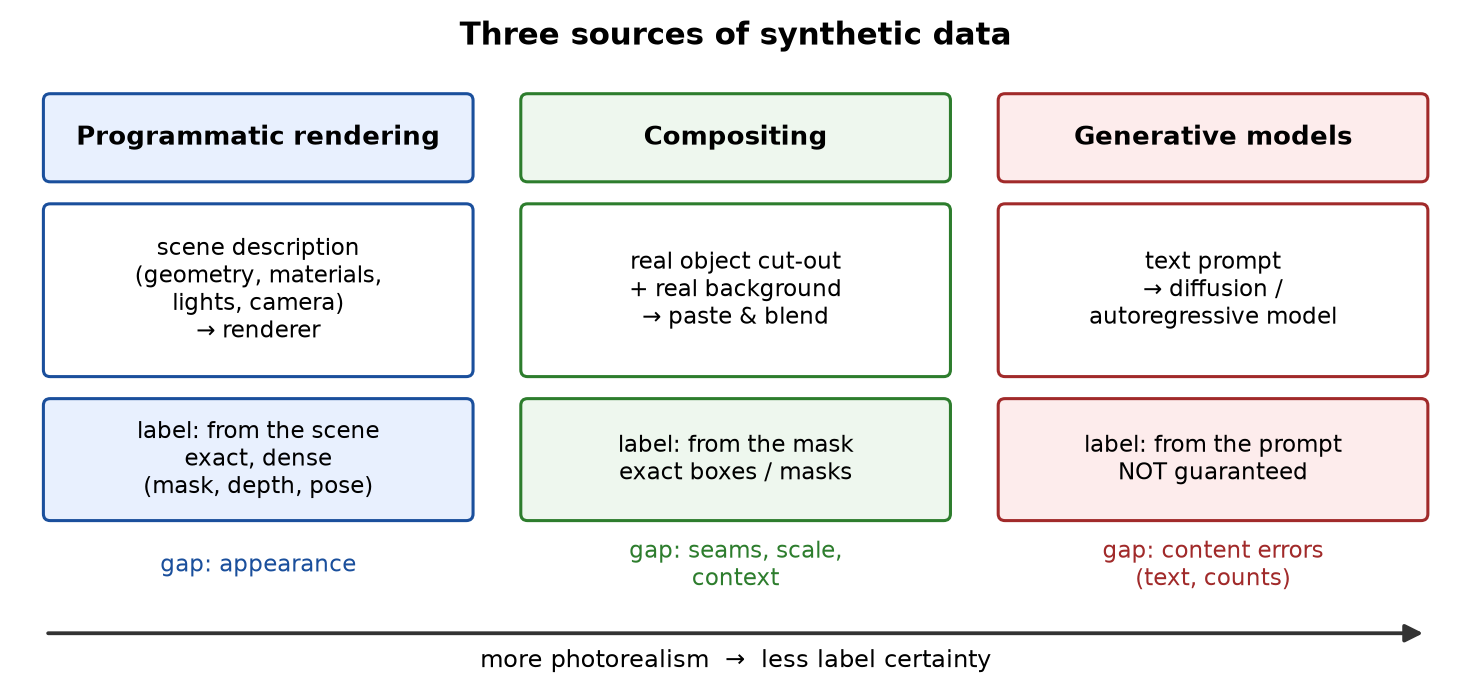

Три источника различаются тем, откуда берётся метка и насколько изображение похоже на реальное.

| Источник | Как получается изображение | Откуда метка | Сильная сторона | Слабая сторона |
|---|---|---|---|---|
| Программный рендеринг | 3D-движок, 2D-графика, код | из сцены, точная | любые плотные метки, полный контроль | разрыв по внешнему виду, нужны ассеты |
| Compositing | вырезанный объект на реальном фоне | из маски объекта, точная | реальные фоны и текстуры | швы, неверный масштаб и контекст |
| Генеративные модели | диффузия, авторегрессия по промпту | из промпта, не гарантирована | фотореализм, длинный хвост контекстов | метка может не совпадать с содержимым |

### 2.1. Программный рендеринг

Рендеринг строит изображение из явного описания сцены: геометрия, материалы, свет, камера. Метки получаются как побочный продукт: маска — это идентификатор объекта в каждом пикселе, глубина — z-буфер, поза — параметры размещения объекта.

Инструменты разного уровня:

- 3D-движки и конвейеры поверх Blender: BlenderProc — модульный процедурный конвейер для фотореалистичных обучающих изображений с метками сегментации, глубины, нормалей и позы ([Denninger et al., 2019](https://arxiv.org/abs/1911.01911)); Kubric соединяет Blender и PyBullet, масштабируется на тысячи машин и включает 13 сгенерированных датасетов ([Greff et al., 2022](https://arxiv.org/abs/2203.03570)).
- Процедурная генерация миров: Infinigen создаёт фотореалистичные природные 3D-сцены целиком процедурно, из случайных математических правил, без внешних ассетов ([Raistrick et al., 2023](https://arxiv.org/abs/2306.09310)).
- Игры и готовые симуляторы: в Playing for Data метки сегментации получены для 25 тысяч кадров компьютерной игры, а модель, обученная на них вместе с третью CamVid, превзошла модель на полном CamVid ([Richter et al., 2016](https://arxiv.org/abs/1608.02192)); Virtual KITTI воспроизводит сцены KITTI в движке Unity ([Gaidon et al., 2016](https://arxiv.org/abs/1605.06457)).
- 2D-рендеринг: текст, документы, графики, интерфейсы. SynthDoG рендерит документы с фонами из ImageNet, текстом из Википедии и шрифтами Noto — по 0,5 миллиона изображений на английском, китайском, японском и корейском, всего 2 миллиона ([Kim et al., 2022](https://arxiv.org/pdf/2111.15664)). В практикуме мы рендерим цифры шрифтами, это та же идея в миниатюре.

Главная слабость рендеринга — внешний вид. Материалы, шум сенсора, оптика, грязь и износ в реальном мире сложнее, чем в сцене, и модель может выучить признаки, которые есть только в рендере.

### 2.2. Compositing

Compositing берёт реальные пиксели и меняет только композицию: объект вырезается по маске и вставляется на другой фон. Метка точная, потому что известны маска и положение вставки.

- Cut, Paste and Learn: экземпляры объектов вырезаются и вставляются на случайные фоны, а детектор учат не обращать внимания на артефакты на границах (размытие и разные режимы смешивания краёв). Вместе с реальными изображениями это дало относительный прирост более 21%, а в кросс-доменной постановке синтетика плюс 10% реальных данных превзошла все реальные данные ([Dwibedi et al., 2017](https://arxiv.org/abs/1708.01642)).
- Copy-Paste как аугментация: случайная вставка объектов из одного изображения в другое без моделирования контекста дала 49,1 mask AP и 57,3 box AP на COCO и +3,6 mask AP на редких классах LVIS по сравнению с победителем LVIS Challenge 2020 ([Ghiasi et al., 2021](https://arxiv.org/abs/2012.07177)).
- SynthText вставляет текст в реальные фотографии с учётом локальной 3D-геометрии сцены, чтобы надпись лежала на поверхности ([Gupta et al., 2016](https://arxiv.org/abs/1604.06646)).

Слабости: видимые швы, неверный масштаб и освещение, нереалистичный контекст (корова на потолке). Интересно, что для обучения детекторов реалистичный контекст оказывается менее важен, чем можно ожидать: Copy-Paste работает и со случайным размещением.

### 2.3. Генеративные модели

Диффузионные модели рисуют фотореалистичные изображения по текстовому описанию, и это делает их привлекательным источником данных для классификации.

- He et al. на ICLR 2023 показали, что синтетика от text-to-image модели улучшает zero-shot CLIP на 17 датасетах: средняя точность RN50 выросла с 55,13 до 59,47, ViT-B/16 — с 65,42 до 68,32, на EuroSAT прирост 17,86 пункта. Решающими были два приёма: языковое расширение промптов для разнообразия и фильтрация сгенерированных изображений по CLIP для чистоты меток ([He et al., 2023](https://arxiv.org/pdf/2210.07574)).
- Azizi et al. дообучили Imagen на ImageNet как class-conditional модель: FID 1,76 на 256×256, а классификатор, обученный только на сгенерированных изображениях, достиг Classification Accuracy Score 64,96 при 256×256 и 69,24 при 1024×1024 ([Azizi et al., 2023](https://arxiv.org/abs/2304.08466)).
- «Fake it till you make it»: клоны ImageNet от Stable Diffusion закрывают большую часть разрыва с реальными данными, а представления переносятся на другие задачи на уровне реальных ([Sariyildiz et al., 2023](https://arxiv.org/abs/2212.08420)).
- StableRep: с языковым надзором модель, обученная на 20 миллионах синтетических изображений, точнее CLIP, обученного на 50 миллионах реальных ([Tian et al., 2023](https://arxiv.org/abs/2306.00984)).

Главная проблема — метка не гарантирована. Промпт «house number 7» не означает, что на картинке будет семёрка: модель может нарисовать другую цифру, несколько цифр или псевдобуквы. Тексты, счёт и пространственные отношения — известные слабые места text-to-image моделей. Поэтому генеративная синтетика без проверки — это данные с систематическим шумом разметки. Отсюда в конвейере появляются шаги 3.4–3.6.

В практикуме используется SD-Turbo — дистилляция Stable Diffusion 2.1 методом Adversarial Diffusion Distillation, которая генерирует 512×512 за 1–4 шага и запускается с `guidance_scale=0.0` ([SD-Turbo model card](https://huggingface.co/stabilityai/sd-turbo); [Sauer et al., 2023](https://arxiv.org/abs/2311.17042)).

### 2.4. Domain randomization

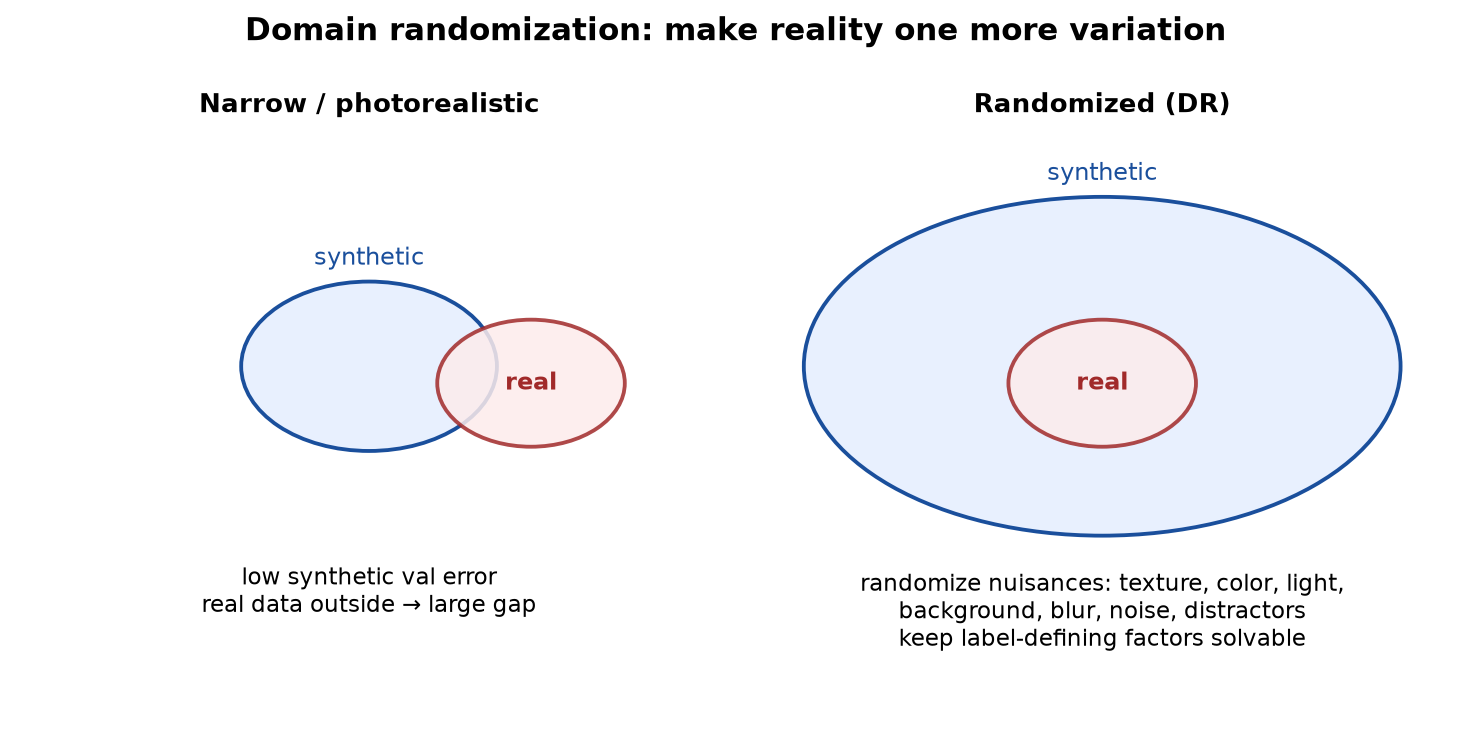

Domain randomization (DR) переворачивает задачу. Вместо того чтобы делать рендер максимально реалистичным, мы делаем его максимально разнообразным: случайные текстуры, свет, камера, шум, отвлекающие объекты. Если разнообразие достаточно велико, реальный мир выглядит для модели просто ещё одной вариацией.

Tobin et al. учили детектор позиции объектов только на симуляции с нереалистичными текстурами: случайный RGB, градиент между двумя цветами или шахматная доска, случайные положение камеры, освещение, шум и от 0 до 10 отвлекающих объектов. На реальных изображениях детектор локализовал объекты с точностью до 1,5 см; относительно точное обнаружение появлялось уже при 5 тысячах обучающих примеров, а дальше качество росло примерно до 50 тысяч ([Tobin et al., 2017](https://arxiv.org/abs/1703.06907)).

Tremblay et al. перенесли DR на детекцию автомобилей KITTI и сравнили с фотореалистичным Virtual KITTI ([Tremblay et al., 2018](https://arxiv.org/pdf/1804.06516)):

| Детектор | AP@0.5, обучение на VKITTI | AP@0.5, обучение на DR |
|---|---|---|
| Faster R-CNN | 79,7 | 78,1 |
| R-FCN | 64,6 | 71,5 |
| SSD | 36,1 | 46,3 |

После дообучения на 6 тысячах реальных изображений DR дала 98,5 против 96,5 у модели только на реальных данных и 98,0 у VKITTI ([Tremblay et al., 2018](https://arxiv.org/pdf/1804.06516)). Два вывода: нереалистичная, но разнообразная синтетика может быть не хуже реалистичной, а лучший результат даёт сочетание с реальными данными.

Structured domain randomization (SDR) добавляет к случайности структуру: объекты и отвлекающие элементы размещаются по распределениям, связанным с контекстом сцены (машины на дороге, а не в небе). На KITTI SDR превзошла VKITTI, Sim 200k, обычную DR и реальные данные из другого домена BDD100K, а SDR вместе с реальными KITTI — одни реальные KITTI ([Prakash et al., 2019](https://arxiv.org/abs/1810.10093)). Meta-Sim идёт дальше и учит параметры генератора сцен так, чтобы распределение синтетики приблизилось к целевому ([Kar et al., 2019](https://arxiv.org/abs/1904.11621)).

Практический смысл DR: варьировать нужно то, что модель не должна использовать как признак (цвет фона, шрифт, шум), и не варьировать то, что определяет метку. Если перестараться, задача становится неразрешимой: цифра того же цвета, что фон, — это уже не трудный пример, а неверный.

## 3. Конвейер синтетических данных

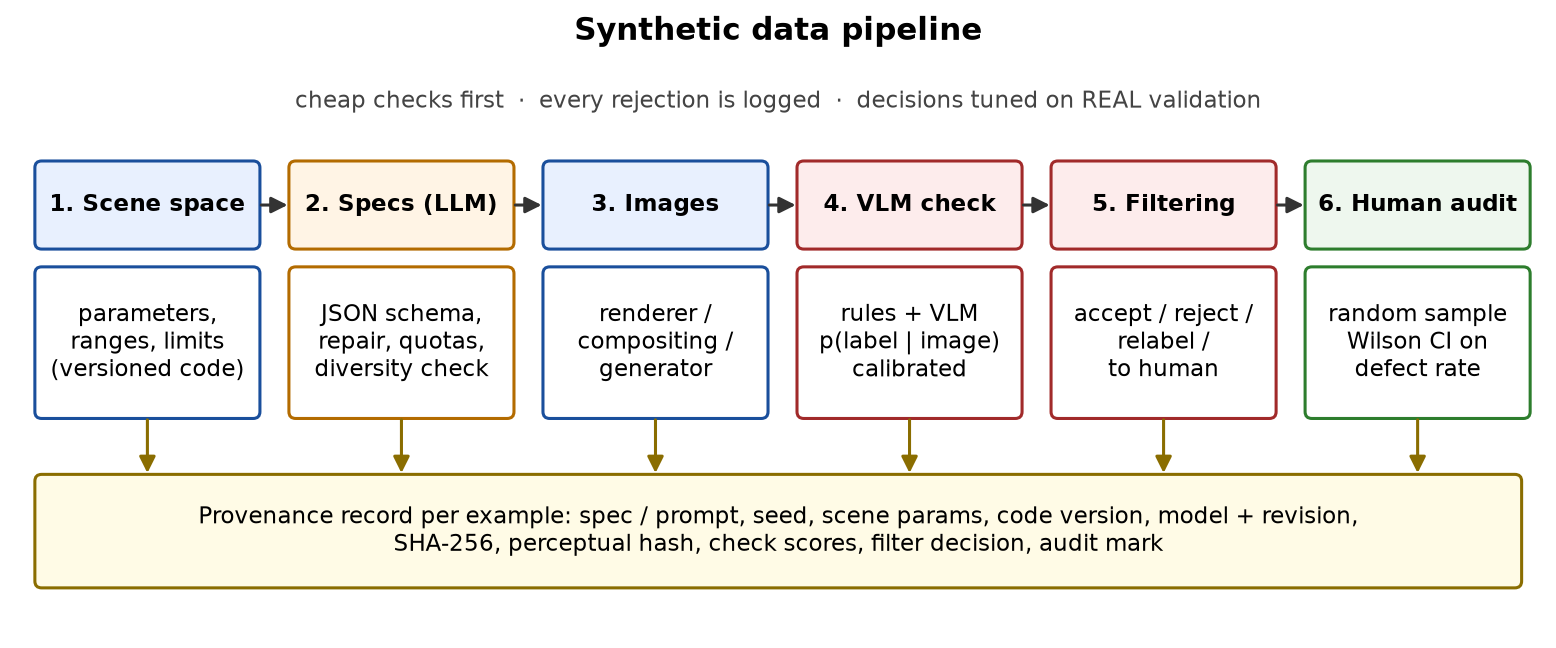

Конвейер из шести шагов: пространство сцен → спецификации (LLM) → изображения → проверка VLM → фильтрация → ручной аудит. Через все шаги проходит provenance: каждый шаг дописывает в запись примера, что он сделал. Порядок важен: дешёвые проверки стоят раньше дорогих, автоматические — раньше ручных, и на каждом шаге отбраковка записывается, а не просто выполняется.

### 3.1. Пространство сцен

Пространство сцен — формальное описание того, что может быть на изображении: список параметров, их типы и допустимые значения. Для цифр это цифра, шрифт, цвет текста и фона, фон, наклон, масштаб, соседние цифры, размытие, шум, JPEG-сжатие. Для детекции машин — дорога, число и типы машин, погода, время суток, камера.

Три требования к пространству сцен:

- Покрытие. Пространство должно содержать реальное распределение как подмножество, иначе domain randomization не поможет: модель не увидит того, чего нет в пространстве.
- Разрешимость. Каждая точка пространства должна давать изображение, на котором метку можно определить. Ограничения («контраст текста и фона не ниже порога») записываются в описании пространства, а не ловятся потом фильтром.
- Версионирование. Пространство — это код, у него есть версия. Две выборки из разных версий — разные датасеты, даже если они выглядят похоже.

Сэмплер выбирает точки пространства: равномерно, по квотам (по 10% каждой цифры), по стратам (каждое сочетание «фон × освещение» не реже заданного) или по распределению, подобранному под реальные данные, как в SDR и Meta-Sim (раздел 2.4).

### 3.2. Спецификации от LLM

Спецификация — конкретная точка пространства сцен в машиночитаемом виде, обычно JSON. Её может выдать сэмплер, а может LLM. Зачем LLM, если есть сэмплер? Сэмплер не знает мира: он не знает, что номер на кирпичной стене обычно белый на синем, а табличка ночью подсвечена. LLM знает такие связи и может выдавать семантически согласованные сцены и длинный хвост контекстов.

Примеры подхода:

- LayoutGPT: LLM по текстовому запросу генерирует раскладку объектов (рамки в синтаксисе, похожем на CSS) по нескольким примерам в контексте; по числовой и пространственной корректности это на 20–40% лучше, чем у text-to-image моделей, и сравнимо с людьми ([Feng et al., 2023](https://arxiv.org/abs/2305.15393)).
- LMD (LLM-grounded Diffusion): LLM строит раскладку с подписями к рамкам, затем диффузионная модель рисует по раскладке; без дообучения это в среднем вдвое повышает точность генерации на четырёх задачах ([Lian et al., 2023](https://arxiv.org/abs/2305.13655)).
- CoSyn: LLM пишет не изображение, а код, который его рендерит, и затем инструкции по этому коду ([Yang et al., 2025](https://arxiv.org/pdf/2502.14846)).

Как сделать вывод LLM пригодным для конвейера:

1. JSON-схема с типами, диапазонами и перечислениями значений. Ответ, не прошедший схему, отклоняется или запрашивается заново с сообщением об ошибке.
2. Семантические проверки поверх схемы. Схема пропустит текст того же цвета, что фон; это ловит отдельное правило.
3. Квоты в коде, а не в промпте. LLM плохо держит баланс: просьба «сделай разнообразно» не даёт равномерного распределения цифр, цветов и сцен. Метку и числовые параметры задаёт код, а LLM — только семантические поля.
4. Измерение разнообразия: энтропия значений каждого поля, доля уникальных спецификаций, число повторов. Коллапс разнообразия (mode collapse) у LLM — норма, а не исключение.

### 3.3. Изображения

Исполнитель превращает спецификацию в изображение: рендерер, compositing или генеративная модель. Для воспроизводимости исполнитель должен быть детерминированным при фиксированных спецификации и seed, а всё, что влияет на результат, — записано: версия кода, версии и ревизии моделей, число шагов, guidance, разрешение, scheduler. Отдельный вопрос — детерминизм на GPU: часть операций CUDA недетерминирована, поэтому для проверки повторяемости сравнивают не только хэши, но и перцептивную близость.

### 3.4. Проверка VLM

Если метка не известна по построению (генеративная модель) или исполнитель мог ошибиться (баг рендерера, неудачный compositing), нужен проверяющий, который смотрит на пиксели. Основные метрики соответствия изображения и текста:

- CLIPScore — косинусная близость CLIP-эмбеддингов изображения и текста, без эталонов ([Hessel et al., 2021](https://arxiv.org/abs/2104.08718)). Быстрая, но плохо различает счёт, отношения и атрибуты.
- TIFA — LLM превращает описание в набор вопросов с ответами, VQA-модель отвечает на них по изображению, доля правильных ответов — оценка. Бенчмарк TIFA v1.0 — 4 тысячи текстов и 25 тысяч вопросов ([Hu et al., 2023](https://arxiv.org/abs/2303.11897)).
- DSG (Davidsonian Scene Graph) — те же вопросы, но в виде графа зависимостей: вопрос об атрибуте объекта не задаётся, если на вопрос о существовании объекта получен ответ «нет» ([Cho et al., 2024](https://arxiv.org/abs/2310.18235)).
- VQAScore — вероятность ответа «Yes» на вопрос «Does this figure show {text}?» у VQA-модели ([Lin et al., 2024](https://arxiv.org/abs/2404.01291)).

Для задачи с закрытым набором классов, как в практикуме, проще и сильнее спросить VLM прямо («какая цифра?») и взять вероятность метки из распределения по классам.

Проверяющий сам ошибается, и важно как:

- Ошибки проверяющего не случайны. Слабая VLM чаще отклоняет трудные исправные примеры (маленький объект, шум, необычный ракурс), и фильтр сдвигает датасет к лёгким примерам. Это прямо противоречит цели domain randomization.
- Смещение проверяющего переходит в данные. Если VLM-судья предпочитает определённый стиль, фильтр по нему отбирает этот стиль.
- Проверяющий не должен совпадать с моделью, которую вы потом будете оценивать: иначе оценка измеряет согласие модели с самой собой.

Поэтому проверяющего калибруют на размеченной выборке с известными дефектами: строят ROC, выбирают порог и отдельно смотрят, каких исправных примеров он отбрасывает больше.

### 3.5. Фильтрация

Фильтр решает, что делать с примером по результатам проверок: оставить, отбросить, исправить метку или отправить на ручной просмотр. Хорошая практика — каскад:

1. Правила исполнителя (бесплатно, точно, но только для известных дефектов): объект в кадре, контраст, площадь маски, валидность спецификации.
2. Модельные проверки (дороже, ловят несоответствие метки и содержимого): VLM, ансамбль классификаторов.
3. Серая зона — на ручной просмотр, а не в мусор.

Порог фильтра — компромисс между двумя ошибками: пропущенные дефекты (шум разметки в обучении) и отброшенные исправные примеры (потеря разнообразия). Его выбирают по последствиям для качества на реальной валидации, а не по «красивому» значению метрики проверяющего.

### 3.6. Ручной аудит

После автоматики остаётся вопрос: сколько дефектов прошло фильтр. Ответ даёт ручной аудит случайной выборки из принятых примеров. Если в выборке из $n$ примеров найдено $k$ дефектов, долю дефектов $p$ оценивают интервалом Уилсона:

$$ \hat p = \frac{k}{n}, \qquad \frac{\hat p + \frac{z^2}{2n} \pm z\sqrt{\frac{\hat p(1-\hat p)}{n} + \frac{z^2}{4n^2}}}{1 + \frac{z^2}{n}}, \qquad z = 1{,}96. $$

Интервал Уилсона, в отличие от нормального приближения, не выходит за $[0, 1]$ и работает при $k = 0$: даже если в 100 примерах не найдено ни одного дефекта, верхняя граница 95%-интервала около 3,7%. Отсюда практическое правило: объём аудита выбирают под требуемую верхнюю границу, а не «сколько успеем».

Аудит стоит стратифицировать по источнику (рендер, compositing, генерация), по классу и по решению фильтра, а аудитору не показывать решение автоматики. Результат аудита записывается в provenance и в карточку датасета.

## 4. Provenance

### 4.1. Что записывать

Provenance — запись о происхождении примера, достаточная, чтобы ответить на три вопроса: откуда пример взялся, как получить его заново и почему он в датасете. Минимальный состав записи:

| Группа | Поля |
|---|---|
| Идентичность | `id`, источник (render, composite, generative), метка, путь к файлу |
| Воспроизведение | спецификация или параметры сцены, prompt и negative prompt, seed, версия кода исполнителя, модель и её ревизия, число шагов, guidance, разрешение |
| Внешние ресурсы | идентификаторы и хэши шрифтов, текстур, фонов; их лицензии |
| Контроль | SHA-256 пикселей, перцептивный хэш, результаты проверок с версиями проверяющих, решение фильтра, отметка аудита |
| Окружение | версии библиотек, устройство, дата |

Seed без версии кода ничего не воспроизводит: тот же seed в новой версии рендерера даёт другое изображение. Поэтому версия исполнителя — это хэш его кода, а не номер, который кто-то забудет обновить. Для генеративных моделей — ревизия (коммит) на хабе, а не имя модели: веса под тем же именем могут измениться.

### 4.2. Зачем это нужно

- Отладка. Если модель ошибается на определённом типе примеров, по provenance находят параметры, которые их породили, и правят пространство сцен, а не случайные изображения.
- Дедупликация и утечки. Идентичные спецификации и хэши находят повторы дешевле, чем сравнение пикселей (раздел 5).
- Аудит и удаление. Если обнаружилась проблема с фоном, шрифтом или лицензией, по provenance удаляют все зависящие от него примеры.
- Честное сравнение. Два эксперимента сравнимы, только если известно, на каких именно данных они обучены.

### 4.3. Документация датасета

На уровне датасета provenance превращается в документацию. Datasheets for Datasets предлагают для каждого датасета описывать мотивацию, состав, процесс сбора, предобработку, предполагаемые применения, распространение и сопровождение ([Gebru et al., 2021](https://arxiv.org/abs/1803.09010)). Data Cards — структурированные сводки с объяснениями происхождения, процессов и решений, принятых при создании датасета ([Pushkarna et al., 2022](https://arxiv.org/abs/2204.01075)). Для синтетики в карточку добавляют то, чего нет у реальных датасетов: описание пространства сцен, генераторы с ревизиями, параметры фильтрации, результаты аудита с интервалом и результаты проверки утечек в test.

## 5. Дедупликация

### 5.1. Откуда в синтетике дубликаты

Казалось бы, у программного генератора дубликатов быть не может. Они появляются из-за:

- повторных спецификаций: LLM выдаёт одни и те же сценарии, сэмплер с маленьким пространством повторяет точки;
- повторного seed при перезапуске части конвейера;
- маленьких пулов ресурсов: 20 шрифтов × 10 цифр × простой фон дают мало действительно разных изображений;
- генеративных моделей, которые на похожих промптах рисуют почти одно и то же.

Дубликаты в обучении сдвигают веса примеров и тратят бюджет. Дубликаты между обучением и test завышают оценку — это утечка.

### 5.2. Лестница методов

| Уровень | Метод | Что находит | Ложные совпадения |
|---|---|---|---|
| 0 | идентификатор спецификации | повтор параметров | нет |
| 1 | SHA-256 пикселей | точные копии | нет |
| 2 | перцептивный хэш (dHash, pHash), расстояние Хэмминга | перекодирование, лёгкий шум, ресайз | мало |
| 3 | эмбеддинги (CLIP, DINO, SSCD), косинусная близость | почти-копии, другой seed той же сцены | зависит от порога |
| 4 | семантическая дедупликация по кластерам эмбеддингов | семантические повторы | много, это уже прореживание |

Чем выше уровень, тем больше видов копий находится и тем больше ложных пар. Порог эмбеддингов выбирают по размеченной выборке пар, а найденные пары просматривают.

SemDeDup кластеризует эмбеддинги и внутри кластера удаляет примеры, близкие к другим; на подмножестве LAION это позволило убрать 50% данных с минимальной потерей качества ([Abbas et al., 2023](https://arxiv.org/abs/2303.09540)). Это уже не удаление копий, а сокращение избыточности: семантически похожие примеры несут мало новой информации.

### 5.3. Утечки и запоминание

Проверку утечек делают между любыми частями, которые не должны пересекаться: синтетика и test, real train и test. Barz и Denzler нашли почти-дубликаты в обучающей выборке для 3,3% изображений test CIFAR-10 и 10% test CIFAR-100 ([Barz, Denzler, 2020](https://arxiv.org/abs/1902.00423)).

Для генеративной синтетики есть ещё один канал утечки: модель запоминает свои обучающие изображения. Carlini et al. извлекли из диффузионных моделей более тысячи обучающих изображений и показали, что главный фактор — дублирование в обучающих данных; для Stable Diffusion среди 350 тысяч наиболее дублированных обучающих изображений нашлось 109, которые модель воспроизводила почти точными копиями ([Carlini et al., 2023](https://arxiv.org/abs/2301.13188)). Если реальный test взят из того же интернета, что и обучающие данные генератора, генератор может «подсмотреть» test. Значит, синтетику от генеративной модели тоже сравнивают с test.

## 6. Отбор сложных примеров

### 6.1. Идея

Синтетику можно производить почти без ограничений, а бюджет обучения ограничен. Разумно тратить его на примеры, которые модель ещё не выучила. Online Hard Example Mining (OHEM) для детекторов выбирает в каждом батче регионы с наибольшим loss и обучает только на них ([Shrivastava et al., 2016](https://arxiv.org/abs/1604.03540)). Для синтетики то же самое делают на уровне пула: обучают оценочную модель, считают loss или неуверенность на кандидатах и оставляют трудные. Можно идти и дальше — смещать сэмплер пространства сцен к параметрам, на которых модель ошибается.

### 6.2. Трудный или сломанный

Самый большой loss у примеров, метка которых неверна. Отбор по loss без очистки собирает в выборку именно шум разметки: для модели неверно размеченный пример и есть самый трудный. Это особенно опасно для генеративной синтетики, где неверные метки систематические. Практичный порядок: сначала убрать уверенные несогласия (модель уверенно предсказывает другой класс; это идея confident learning из лекции 7), затем отбирать трудные среди оставшихся и выборочно просматривать их.

### 6.3. Трудные или лёгкие: зависит от объёма

Sorscher et al. показали теоретически и проверили на практике, что лучшая стратегия прореживания данных зависит от их количества: при большом объёме данных выгоднее оставлять трудные примеры, а при малом — лёгкие ([Sorscher et al., 2022](https://arxiv.org/abs/2206.14486)). Интуиция: при малом бюджете модели сначала нужно выучить основную структуру задачи, а трудные примеры для неё пока шум. Поэтому стратегию отбора сравнивают с равным по размеру случайным отбором на реальной валидации.

## 7. Domain gap

### 7.1. Оценка через расстояние между доменами

Пусть $S$ — распределение синтетики (source), $T$ — реальное распределение (target), $h$ — классификатор из класса $\mathcal H$, $\varepsilon_S(h)$ и $\varepsilon_T(h)$ — его ошибки на этих распределениях. Ben-David et al. доказали оценку ([Ben-David et al., 2010](https://link.springer.com/article/10.1007/s10994-009-5152-4)):

$$ \varepsilon_T(h) \;\le\; \varepsilon_S(h) \;+\; \tfrac{1}{2}\, d_{\mathcal H \Delta \mathcal H}(S, T) \;+\; \lambda, \qquad \lambda = \min_{h' \in \mathcal H} \big[\varepsilon_S(h') + \varepsilon_T(h')\big]. $$

Три слагаемых — три рычага:

- $\varepsilon_S(h)$ — ошибка на синтетике. Её мы минимизируем при обучении, и её показывает синтетическая валидация. Она почти всегда маленькая, поэтому одна она ничего не говорит о $\varepsilon_T$.
- $d_{\mathcal H \Delta \mathcal H}(S, T)$ — насколько классификаторы из $\mathcal H$ могут по-разному вести себя на двух доменах; на практике — насколько домены различимы. Её уменьшают domain randomization, реальные фоны, реалистичный рендеринг и выравнивание признаков (DANN).
- $\lambda$ — ошибка лучшей общей гипотезы. Если в синтетике метки определяются иначе, чем в реальности (неверные метки генеративной модели, нерешаемые сцены), $\lambda$ велика и никакое выравнивание не поможет. Её уменьшают проверка и фильтрация (разделы 3.4–3.6).

Отсюда главный вывод для протокола: малая ошибка на синтетической валидации — необходимое, но не достаточное условие. Оценка $\varepsilon_T$ требует реальных данных.

### 7.2. Как измерить разрыв

Proxy A-distance (PAD). Обучим доменный классификатор отличать синтетику от реальных изображений и измерим его ошибку $\epsilon$ на отложенной выборке. Тогда

$$ \hat d_{\mathcal A} = 2\,(1 - 2\epsilon). $$

При $\epsilon = 0{,}5$ (домены неразличимы) $\hat d_{\mathcal A} = 0$, при $\epsilon = 0$ — максимум 2 ([Ganin et al., 2016](https://arxiv.org/pdf/1505.07818)). PAD быстро насыщается: если доменный классификатор отличает домены почти безошибочно по малозаметным деталям (характер шума, резкость краёв), PAD близка к 2 у всех вариантов синтетики, даже если они сильно различаются по полезности.

Fréchet distance (FD) между гауссовыми аппроксимациями признаков двух выборок, как в FID ([Heusel et al., 2017](https://arxiv.org/abs/1706.08500)):

$$ \mathrm{FD} = \lVert \mu_S - \mu_T \rVert_2^2 + \operatorname{Tr}\!\Big(\Sigma_S + \Sigma_T - 2\,(\Sigma_S \Sigma_T)^{1/2}\Big). $$

Значение FD зависит от экстрактора признаков. В FID это Inception, обученная на ImageNet; для цифр 32×32 разумнее признаки модели нашей задачи. FD сравнима только при одинаковых экстракторе и размерах выборок.

Ни одна мера разрыва не заменяет оценку на реальном test: они полезны для быстрого сравнения вариантов синтетики, но могут не совпадать с ранжированием по точности.

### 7.3. Выравнивание доменов

DANN (Domain-Adversarial Neural Network) добавляет к классификатору доменный классификатор, который через слой обращения градиента учит признаки быть неразличимыми между доменами. В постановке Syn Numbers → SVHN (около 500 тысяч цифр, нарисованных шрифтами Windows с варьированием положения, ориентации, цвета фона и штриха и размытия) обучение только на синтетике дало 0,8674 на SVHN, DANN — 0,9109, обучение на размеченном SVHN — 0,9220: DANN закрыл 79,7% разрыва ([Ganin et al., 2016](https://arxiv.org/pdf/1505.07818)). Это та же задача, что в нашем практикуме, только с синтетикой в 25 раз больше и с обучением на неразмеченных реальных изображениях.

## 8. Смеси real/synthetic

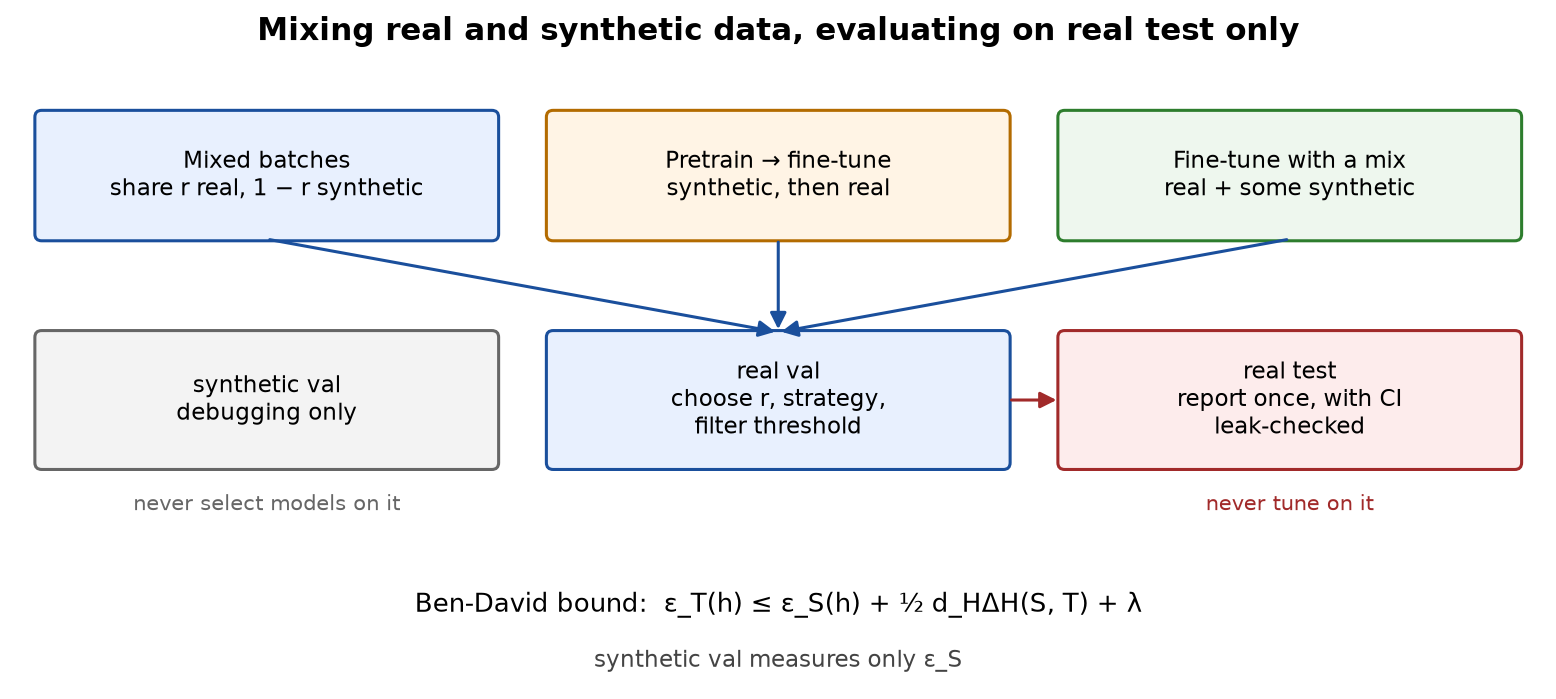

### 8.1. Почему смесь

Почти во всех работах этой лекции лучший результат даёт не синтетика и не реальные данные, а их сочетание:

- Playing for Data: игровые кадры вместе с третью CamVid лучше полного CamVid ([Richter et al., 2016](https://arxiv.org/abs/1608.02192));
- Cut, Paste and Learn: синтетика плюс 10% реальных данных лучше всех реальных данных в кросс-доменной постановке ([Dwibedi et al., 2017](https://arxiv.org/abs/1708.01642));
- Tremblay et al.: DR с дообучением на 6 тысячах реальных изображений лучше одних реальных данных ([Tremblay et al., 2018](https://arxiv.org/pdf/1804.06516));
- SDR вместе с реальными KITTI лучше одних реальных KITTI ([Prakash et al., 2019](https://arxiv.org/abs/1810.10093)).

Синтетика даёт покрытие, разнообразие и точные метки, реальные данные — правильное распределение внешнего вида и $\lambda$, близкую к нулю. Практический вопрос: сколько реальных данных можно заменить синтетикой при заданном качестве.

### 8.2. Стратегии

1. Совместное обучение (mixed): каждый батч содержит долю $r$ реальных примеров и $1 - r$ синтетических. Параметр $r$ подбирают; реальных примеров обычно мало, поэтому они повторяются чаще синтетических.
2. Предобучение и дообучение (pretrain → fine-tune): сначала на синтетике, потом на реальных данных. Синтетика работает как инициализация.
3. Дообучение со смесью: на втором этапе к реальным данным добавляют немного синтетики, чтобы не забыть покрытие.

Nowruzi et al. систематически изучали для детекции объектов, что происходит при замене реальных данных синтетическими и при ограниченном объёме реальных данных, на нескольких синтетических и реальных датасетах с анализом их доменной близости ([Nowruzi et al., 2019](https://arxiv.org/abs/1907.07061)). Какая стратегия лучше, зависит от задачи и объёмов, поэтому стратегию и $r$ выбирают на реальной валидации.

### 8.3. Кривая замещения

Хороший способ показать пользу синтетики — кривая качества на real test в зависимости от числа реальных примеров $N_{\text{real}}$ для двух условий: только реальные данные и реальные плюс синтетика. Горизонтальное расстояние между кривыми показывает, сколько реальных примеров «стоит» синтетика. Обычно выигрыш большой при малом $N_{\text{real}}$ и уменьшается с его ростом.

## 9. Оценка только на реальном test set

### 9.1. Протокол

Правило простое: качество модели, обученной на синтетике, оценивают на реальных данных из целевого распределения, которые не участвовали ни в обучении, ни в выборе чего бы то ни было.

| Выборка | Для чего | Чего с ней делать нельзя |
|---|---|---|
| synthetic val | отладка: рендерер и обучение не сломаны | выбирать модели, пороги, рецепты синтетики |
| real val | выбор гиперпараметров, доли $r$, порога фильтра, стратегии отбора, ранняя остановка | отчитываться итоговым числом |
| real test | одно итоговое измерение для каждого финального варианта | подбирать что-либо, смотреть ошибки и править под них |

### 9.2. Почему synthetic val вводит в заблуждение

Синтетическая валидация измеряет $\varepsilon_S$. Чем уже пространство сцен, тем легче задача на синтетике и тем больше разрыв. Поэтому выбор по синтетической валидации систематически предпочитает узкую синтетику — ровно ту, которая хуже переносится. В практикуме это видно в разделе 13.

### 9.3. Скрытые утечки в выбор

Real test «изнашивается» не только когда на нём обучают. Каждый раз, когда по нему выбирают рецепт синтетики, порог VLM-фильтра или долю смеси, он превращается в валидацию, и оценка становится оптимистичной. Отсюда:

- все решения конвейера синтетики принимаются по real val;
- real test проверяется на утечки из синтетики и real train (раздел 5.3);
- если реального test мало, итог дают с доверительным интервалом (бутстреп), а разницы меньше ширины интервала не интерпретируют;
- для генеративной синтетики проверяют, не входят ли изображения test в обучающие данные генератора, или хотя бы ищут почти-копии test среди сгенерированного.

Для VLM то же правило формулируется так: бенчмарк, на котором вы отчитываетесь, должен состоять из реальных изображений и не пересекаться с источниками, из которых генерировались инструкции.

## 10. Рецепт и типичные ошибки

### 10.1. Рецепт

1. Определите целевое распределение и соберите небольшие real val и real test. Без них синтетику нельзя оценить.
2. Опишите пространство сцен как версионируемый код с ограничениями разрешимости.
3. Начните с программной синтетики с domain randomization: у неё точные метки. Добавьте реальные фоны и текстуры (compositing).
4. LLM используйте для семантики и длинного хвоста контекстов, но с JSON-схемой, ремонтом формата, квотами в коде и измерением разнообразия.
5. Генеративные модели используйте там, где нужен внешний вид, которого не даёт рендер, и только с проверкой содержимого.
6. Проверки: сначала правила, затем VLM, откалиброванная на примерах с известными дефектами; следите, каких исправных примеров она отбрасывает.
7. Ручной аудит случайной выборки принятых примеров с интервалом Уилсона.
8. Дедупликация по лестнице и проверка утечек в test.
9. Смешайте с реальными данными, выберите стратегию и $r$ на real val.
10. Итог — на real test, один раз, с интервалом. Provenance-манифест и карточка датасета — вместе с моделью.

### 10.2. Типичные ошибки

- Выбор рецепта синтетики по синтетической валидации.
- Метка из промпта без проверки содержимого генеративного изображения.
- Фильтр по слабому VLM-проверяющему, который вычищает трудные примеры.
- Отбор «самых трудных» примеров без очистки меток.
- Квоты классов, доверенные LLM.
- Seed без версии кода и ревизии модели в provenance.
- Нет проверки утечек test в синтетику и в данные генератора.
- Синтетика от модели, которую потом оценивают на тех же данных: модель учится на своих же ошибках.

### 10.3. Обучение на собственных генерациях

Отдельный риск возникает, когда генеративные модели обучаются на данных, порождённых предыдущими поколениями моделей. Shumailov et al. показали, что при обучении поколение за поколением на сгенерированных данных модели теряют хвосты исходного распределения и деградируют; это явление названо model collapse ([Shumailov et al., 2024](https://www.nature.com/articles/s41586-024-07566-y)). Для синтетики в CV и VLM вывод практический: реальные данные в обучающей смеси нужны не только для качества, но и для того, чтобы распределение не сужалось от итерации к итерации, а provenance нужен, чтобы знать, какая доля данных сгенерирована.

# Часть II. Практикум

## 11. Подготовка: задача, среда, реальные данные

### 11.1. Задача практикума

Нужен домен, где синтетика нужна и полезна, но разрыв с реальностью измерим и велик. Возьмём классическую пару из работ по domain adaptation: распознавание цифр на фотографиях домовых номеров SVHN ([Netzer et al., 2011](http://ufldl.stanford.edu/housenumbers/)) с обучением на синтетических цифрах. Ровно такая постановка, Syn Numbers → SVHN, есть в статье DANN: около 500 тысяч цифр, нарисованных шрифтами Windows, с варьированием положения, ориентации, цвета фона и штриха и размытия ([Ganin et al., 2016](https://arxiv.org/pdf/1505.07818)).

Почему этот домен удобен для лекции:

- синтетику можно сделать тремя способами из раздела 2: рендерингом шрифтов, compositing на реальные фоны и генеративной моделью;
- у программной синтетики метка известна точно, а у генеративной — нет, и это видно на первом же изображении;
- реальный test set большой (26 032 цифры), поэтому разницу между подходами можно оценить с доверительными интервалами;
- одна эпоха маленькой CNN на 32×32 длится секунды, и на CPU помещается два десятка обучений.

План практикума:

| Раздел | Что делаем | Что увидим |
|---|---|---|
| 11 | среда, реальные данные, честное разбиение | real train pool, real val, real test |
| 12 | пространство сцен, рендерер, provenance | одна запись = одно воспроизводимое изображение |
| 13 | domain randomization: clean → light → full | точность на синтетике и на реальном test расходятся |
| 14 | compositing на реальные фоны | вклад фона в разрыв |
| 15 | спецификации от LLM: схема, валидация, разнообразие | невалидные JSON и коллапс разнообразия |
| 16 | генеративная модель sd-turbo | метка из промпта ≠ содержимое |
| 17 | проверки: правила рендерера и VLM | что ловит каждая проверка и что она отбрасывает зря |
| 18 | фильтрация и ручной аудит | оценка остаточной ошибки с интервалом |
| 19 | дедупликация и проверка утечек | дубликаты внутри синтетики и между real train и real test |
| 20 | отбор сложных примеров | «самые трудные» часто означают «сломанные» |
| 21 | domain gap: доменный классификатор и FD | числа разрыва и их связь с точностью |
| 22 | смеси real/synthetic | сколько реальных данных заменяет синтетика |
| 23 | provenance-манифест и карточка датасета | воспроизводимость и аудит |

Все численные выводы ниже взяты из сохранённого прогона на CPU в режиме `FAST_DEV_RUN`. На GPU выборки больше, числа будут другими; переносить стоит процедуру, а не значения.

In [1]:
import importlib, subprocess, sys

def ensure(pkg, spec=None):
    """Импортирует пакет, а если его нет — ставит через pip."""
    try:
        return importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", spec or pkg], check=False)
        return importlib.import_module(pkg)

import torch
HAS_GPU = torch.cuda.is_available()
for pkg, spec in [("diffusers", "diffusers>=0.30"), ("jsonschema", None), ("pyarrow", None)]:
    ensure(pkg, spec)
import transformers, diffusers, torchvision
print("GPU:", torch.cuda.get_device_name(0) if HAS_GPU else "нет",
      "| torch", torch.__version__, "| transformers", transformers.__version__, "| diffusers", diffusers.__version__)

/home/user/cvtest/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


GPU: нет | torch 2.14.1+cpu | transformers 5.19.0 | diffusers 0.42.0


In [2]:
import os, io, re, gc, json, time, math, random, hashlib, platform, inspect, glob, copy
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np, pandas as pd
import matplotlib, matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont, ImageFilter
import torch.nn as nn, torch.nn.functional as F
import pyarrow.parquet as pq
from huggingface_hub import hf_hub_download, model_info

FAST_DEV_RUN = not HAS_GPU          # на CPU — уменьшенные выборки; на T4 можно поставить False вручную
DEVICE = "cuda" if HAS_GPU else "cpu"
torch.set_num_threads(max(1, os.cpu_count() or 1))
SEED = 0
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if HAS_GPU:
        torch.cuda.manual_seed_all(seed)
seed_everything(SEED)

S = dict(
    n_test=5000 if FAST_DEV_RUN else 26032,     # реальный test: подвыборка на CPU, весь на GPU
    n_val=1000,                                  # реальная валидация (из train, для выбора порогов и смесей)
    n_syn=20000 if FAST_DEV_RUN else 100000,     # синтетика для одного обучения
    epochs=6 if FAST_DEV_RUN else 10,
    n_check=400 if FAST_DEV_RUN else 2000,       # кандидатов на проверку VLM
    n_llm=48 if FAST_DEV_RUN else 240,           # спецификаций от LLM
    n_gen=8 if FAST_DEV_RUN else 64,             # изображений от генеративной модели
    gen_res=384 if FAST_DEV_RUN else 512,
    n_pool=40000 if FAST_DEV_RUN else 200000,    # пул для отбора сложных примеров
)
ART = Path("artifacts_l10"); ART.mkdir(exist_ok=True)
VERSIONS = {"torch": torch.__version__, "transformers": transformers.__version__, "diffusers": diffusers.__version__,
            "numpy": np.__version__, "pillow": Image.__version__, "python": platform.python_version()}
print("FAST_DEV_RUN =", FAST_DEV_RUN, "| device:", DEVICE, "| потоков:", torch.get_num_threads())
print(S)

FAST_DEV_RUN = True | device: cpu | потоков: 2
{'n_test': 5000, 'n_val': 1000, 'n_syn': 20000, 'epochs': 6, 'n_check': 400, 'n_llm': 48, 'n_gen': 8, 'gen_res': 384, 'n_pool': 40000}


### 11.2. Реальные данные и разбиение

Из SVHN берём три непересекающиеся части:

- real train pool — из официального train, из него берутся «немного реальных данных» для смесей в разделе 22;
- real val — 1000 изображений из официального train, не пересекающихся с pool. На них выбираются пороги фильтров и пропорции смесей. Это единственное место, где реальные данные влияют на решения;
- real test — официальный test (на CPU — случайные 5000 из 26 032). Он используется только для итоговых чисел.

Синтетическая валидация тоже будет, но только как отладочный инструмент: «рендерер и обучение не сломаны». Почему её нельзя использовать для выбора модели, станет видно уже в разделе 13.

In [3]:
def load_svhn(split):
    path = hf_hub_download("ufldl-stanford/svhn", f"cropped_digits/{split}-00000-of-00001.parquet", repo_type="dataset")
    t = pq.read_table(path).to_pandas()
    X = np.stack([np.array(Image.open(io.BytesIO(b["bytes"])).convert("RGB")) for b in t.image])
    return X, t.label.values.astype(np.int64)

t0 = time.time()
Xtr_all, ytr_all = load_svhn("train")
Xte_all, yte_all = load_svhn("test")
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(ytr_all))
VAL_IDX, POOL_IDX = perm[:S["n_val"]], perm[S["n_val"]:]
Xval, yval = Xtr_all[VAL_IDX], ytr_all[VAL_IDX]
TEST_IDX = np.sort(rng.permutation(len(yte_all))[:S["n_test"]])
Xte, yte = Xte_all[TEST_IDX], yte_all[TEST_IDX]
print(f"SVHN: train {len(ytr_all)}, test {len(yte_all)} | real val {len(yval)}, real pool {len(POOL_IDX)}, real test {len(yte)} "
      f"| {time.time() - t0:.0f} с")
print("доли классов в real test:", np.round(np.bincount(yte, minlength=10) / len(yte), 3))

SVHN: train 73257, test 26032 | real val 1000, real pool 72257, real test 5000 | 9 с
доли классов в real test: [0.076 0.195 0.155 0.115 0.096 0.085 0.079 0.071 0.065 0.064]


### 11.3. Модель и протокол оценки

Во всех опытах одна и та же маленькая CNN: три свёрточных блока и линейная голова, около 95 тысяч параметров (94 986). Каждое изображение стандартизуется по собственному среднему и разбросу: это убирает часть разрыва в яркости и контрасте между доменами и делает сравнение синтетики честнее.

Функция `train_cnn` принимает список источников с весами: на каждом шаге батч собирается из источников пропорционально весам. Так одной функцией делаются обучение на синтетике, на реальных данных и на смесях с заданной долей реальных примеров в батче.

Оценка — accuracy на real test с 95% бутстреп-интервалом по изображениям. На 5000 изображениях ширина интервала около ±1,3 п. п. при точности 70%, на полном test — около ±0,6 п. п.

In [4]:
class SmallCNN(nn.Module):
    def __init__(self, width=32):
        super().__init__()
        w = width
        block = lambda i, o: [nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU()]
        self.features = nn.Sequential(*block(3, w), nn.MaxPool2d(2), *block(w, 2 * w), nn.MaxPool2d(2),
                                      *block(2 * w, 4 * w), nn.AdaptiveAvgPool2d(1), nn.Flatten())
        self.head = nn.Linear(4 * w, 10)
    def forward(self, x):
        return self.head(self.features(x))

def to_tensor(X):
    """uint8 [N,32,32,3] → float [N,3,32,32] со стандартизацией каждого изображения."""
    x = torch.as_tensor(X).permute(0, 3, 1, 2).float() / 255
    return (x - x.mean((1, 2, 3), keepdim=True)) / (x.std((1, 2, 3), keepdim=True) + 0.05)

def train_cnn(sources, steps, lr=4e-3, init=None, seed=0, bs=128, wd=1e-4):
    """sources: [(X, y, weight), ...]; батч собирается из источников пропорционально весам."""
    seed_everything(seed)
    model = SmallCNN().to(DEVICE)
    if init is not None:
        model.load_state_dict(init)
    data = [(to_tensor(X).to(DEVICE), torch.as_tensor(y).to(DEVICE)) for X, y, _ in sources]
    w = np.array([s[2] for s in sources], dtype=float); w /= w.sum()
    opt = torch.optim.AdamW(model.parameters(), lr=lr / 2, weight_decay=wd)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps)
    g = np.random.default_rng(seed); model.train()
    for step in range(steps):
        counts = g.multinomial(bs, w)
        idx = [torch.randint(len(d[1]), (c,), device=DEVICE) for d, c in zip(data, counts)]
        xb = torch.cat([d[0][i] for d, i in zip(data, idx)]); yb = torch.cat([d[1][i] for d, i in zip(data, idx)])
        loss = F.cross_entropy(model(xb), yb)
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
    return model.eval()

def steps_for(n, epochs=None):
    return max(50, int((epochs or S["epochs"]) * n / 128))

@torch.no_grad()
def predict(model, X, bs=1024):
    model.eval()
    return torch.cat([F.softmax(model(to_tensor(X[i:i + bs]).to(DEVICE)), -1).cpu() for i in range(0, len(X), bs)]).numpy()

def boot_ci(correct, n_boot=1000, seed=0):
    g = np.random.default_rng(seed); c = np.asarray(correct, dtype=float)
    b = c[g.integers(0, len(c), (n_boot, len(c)))].mean(1)
    return c.mean(), np.percentile(b, 2.5), np.percentile(b, 97.5)

RESULTS = {}      # имя опыта → метрики
def evaluate(name, model, X_synval=None, y_synval=None, note=""):
    p = predict(model, Xte)
    acc, lo, hi = boot_ci(p.argmax(1) == yte)
    r = {"real_test": acc, "ci_lo": lo, "ci_hi": hi, "real_val": (predict(model, Xval).argmax(1) == yval).mean()}
    if X_synval is not None:
        r["synth_val"] = (predict(model, X_synval).argmax(1) == y_synval).mean()
    r["note"] = note
    RESULTS[name] = r
    print(f"{name:28s} real test {acc:.3f} [{lo:.3f}, {hi:.3f}]  real val {r['real_val']:.3f}"
          + (f"  synth val {r['synth_val']:.3f}" if "synth_val" in r else ""))
    return r

print("параметров в SmallCNN:", sum(p.numel() for p in SmallCNN().parameters()))

параметров в SmallCNN: 94986


## 12. Пространство сцен, рендерер и provenance

### 12.1. Пространство сцен

Пространство сцен — это явный список параметров, которые меняет генератор, и их допустимых значений. Для домового номера это: цифра, шрифт (21 начертание из шрифтов, которые поставляются с matplotlib и поэтому есть в любой среде Colab), цвета текста и фона, тип фона, размер, поворот, наклон, сдвиг, соседние цифры по краям (в SVHN они почти всегда видны), размытие, шум, контраст, JPEG-сжатие и тень.

Одна точка этого пространства — спецификация (spec): словарь, по которому рендерер детерминированно строит изображение. Всё случайное внутри рендерера (шум, направление градиента) берётся из генератора, инициализированного полем `seed` спецификации. Поэтому пара «спецификация + версия кода» полностью определяет пиксели.

Три уровня domain randomization:

- `clean` — один шрифт, чёрная цифра на белом фоне, по центру, без искажений;
- `light` — все шрифты, небольшой поворот и шум, чёрное на белом или белое на чёрном;
- `full` — все параметры случайны в широких диапазонах; цвета приглушённые, полярность любая, разность яркостей текста и фона не меньше 25–70 (порог тоже случаен), соседние цифры по краям с вероятностью 0,6 с каждой стороны.

In [5]:
FONT_DIR = Path(matplotlib.__file__).parent / "mpl-data" / "fonts" / "ttf"
FONTS = [f for f in ["DejaVuSans.ttf", "DejaVuSans-Bold.ttf", "DejaVuSans-Oblique.ttf", "DejaVuSans-BoldOblique.ttf",
                     "DejaVuSansMono.ttf", "DejaVuSansMono-Bold.ttf", "DejaVuSansMono-Oblique.ttf", "DejaVuSansMono-BoldOblique.ttf",
                     "DejaVuSerif.ttf", "DejaVuSerif-Bold.ttf", "DejaVuSerif-Italic.ttf", "DejaVuSerif-BoldItalic.ttf",
                     "STIXGeneral.ttf", "STIXGeneralBol.ttf", "STIXGeneralItalic.ttf", "STIXGeneralBolIta.ttf",
                     "cmr10.ttf", "cmss10.ttf", "cmtt10.ttf", "cmb10.ttf", "cmti10.ttf"] if (FONT_DIR / f).exists()]
FONT_SHA = {f: hashlib.sha256((FONT_DIR / f).read_bytes()).hexdigest()[:12] for f in FONTS}
_font_cache = {}
def get_font(name, size):
    if (name, size) not in _font_cache:
        _font_cache[(name, size)] = ImageFont.truetype(str(FONT_DIR / name), size)
    return _font_cache[(name, size)]

def glyph_mask(ch, fname, size):
    f = get_font(fname, size)
    l, t, r, b = f.getbbox(ch)
    im = Image.new("L", (r - l + 4, b - t + 4), 0)
    ImageDraw.Draw(im).text((2 - l, 2 - t), ch, font=f, fill=255)
    return im

def make_background(spec, rng, size, textures):
    c0 = np.array(spec["bg_rgb"], dtype=np.float32)
    kind = spec["bg"]
    if kind == "flat":
        return np.tile(c0, (size, size, 1))
    if kind == "photo":                       # compositing: реальная фотография как фон
        tex = textures[spec["bg_tex"] % len(textures)]
        return np.array(tex.resize((size, size), Image.BICUBIC), dtype=np.float32)
    c1 = np.array(spec["bg_rgb2"], dtype=np.float32)
    if kind == "gradient":
        a = rng.uniform(0, 2 * np.pi); yy, xx = np.mgrid[0:size, 0:size] / size
        t = np.cos(a) * xx + np.sin(a) * yy
    else:                                     # "noise": низкочастотная текстура
        t = np.array(Image.fromarray((rng.random((size // 8, size // 8)) * 255).astype(np.uint8)).resize((size, size), Image.BICUBIC), dtype=np.float32)
    t = (t - t.min()) / (np.ptp(t) + 1e-6)
    return c0 * (1 - t[..., None]) + c1 * t[..., None]

def render(spec, textures=None, size=64, out=32, return_mask=False):
    """Спецификация → изображение 32×32 (и маска целевой цифры). Детерминировано при фиксированном spec['seed']."""
    rng = np.random.default_rng(spec["seed"])
    canvas = Image.fromarray(np.clip(make_background(spec, rng, size, textures), 0, 255).astype(np.uint8))
    mask = Image.new("L", (size, size), 0)
    fsize = max(4, int(size * spec["scale"]))
    fg = tuple(int(v) for v in spec["fg_rgb"])
    items = [(str(n["digit"]), n["dx"], False) for n in spec.get("neighbors", [])] + [(str(spec["digit"]), 0.0, True)]
    for ch, ndx, is_target in items:
        g = glyph_mask(ch, spec["font"], fsize).rotate(spec["rotation"], resample=Image.BICUBIC, expand=True)
        sh = spec.get("shear", 0.0)
        if sh:
            g = g.transform((g.width + int(abs(sh) * g.height), g.height), Image.AFFINE,
                            (1, sh, -abs(sh) * g.height if sh > 0 else 0, 0, 1, 0), Image.BICUBIC)
        x0 = int(size / 2 + (spec["dx"] + ndx) * size - g.width / 2); y0 = int(size / 2 + spec["dy"] * size - g.height / 2)
        if spec.get("shadow", 0):
            dark = tuple(int(0.4 * v) for v in spec["bg_rgb"])
            canvas.paste(Image.new("RGB", g.size, dark), (x0 + 2, y0 + 2), g.point(lambda v: int(v * 0.7)))
        canvas.paste(Image.new("RGB", g.size, fg), (x0, y0), g)
        if is_target:
            mask.paste(g, (x0, y0), g)
    if spec.get("blur", 0) > 0:
        canvas = canvas.filter(ImageFilter.GaussianBlur(spec["blur"] * size / 32))
    arr = np.array(canvas.resize((out, out), Image.BILINEAR), dtype=np.float32)
    if spec.get("contrast", 1.0) != 1.0:
        arr = (arr - arr.mean()) * spec["contrast"] + arr.mean()
    if spec.get("noise", 0) > 0:
        arr = arr + rng.normal(0, spec["noise"], arr.shape)
    im = Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8))
    if spec.get("jpeg", 0):
        buf = io.BytesIO(); im.save(buf, "JPEG", quality=int(spec["jpeg"])); im = Image.open(io.BytesIO(buf.getvalue())).convert("RGB")
    if return_mask:
        return im, np.array(mask.resize((out, out), Image.BILINEAR)) / 255.0
    return im

def lum(c):
    return 0.299 * c[0] + 0.587 * c[1] + 0.114 * c[2]

def sample_spec(rng, level, seed, fonts=None, n_tex=0, digit=None):
    """Точка пространства сцен для уровня domain randomization 'clean' | 'light' | 'full'."""
    fonts = fonts or FONTS
    d = int(rng.integers(0, 10)) if digit is None else int(digit)
    base = dict(digit=d, seed=int(seed), level=level)
    if level == "clean":
        return {**base, "font": "DejaVuSans.ttf", "fg_rgb": [0, 0, 0], "bg": "flat", "bg_rgb": [255, 255, 255], "scale": 0.75,
                "rotation": 0.0, "shear": 0.0, "dx": 0.0, "dy": 0.0, "neighbors": [], "blur": 0.0, "noise": 0.0,
                "contrast": 1.0, "jpeg": 0, "shadow": 0}
    if level == "light":
        g = int(rng.integers(0, 2)) * 255
        return {**base, "font": str(rng.choice(fonts)), "fg_rgb": [255 - g] * 3, "bg": "flat", "bg_rgb": [g] * 3,
                "scale": float(rng.uniform(0.6, 0.9)), "rotation": float(rng.uniform(-10, 10)), "shear": 0.0,
                "dx": float(rng.uniform(-0.05, 0.05)), "dy": float(rng.uniform(-0.05, 0.05)), "neighbors": [],
                "blur": 0.0, "noise": float(rng.uniform(0, 8)), "contrast": 1.0, "jpeg": 0, "shadow": 0}
    def muted():
        base_l = rng.uniform(0, 255); tint = rng.normal(0, 1, 3) * rng.uniform(0, 45)
        return [int(np.clip(base_l + t, 0, 255)) for t in tint]
    while True:
        fg, bgc = muted(), muted()
        if abs(lum(fg) - lum(bgc)) > rng.uniform(25, 70):
            break
    kinds = ["flat", "gradient", "noise"] + (["photo", "photo"] if n_tex else [])
    nb = [dict(digit=int(rng.integers(0, 10)), dx=float(side * rng.uniform(0.42, 0.62))) for side in (-1, 1) if rng.random() < 0.6]
    return {**base, "font": str(rng.choice(fonts)), "fg_rgb": fg, "bg": str(rng.choice(kinds)), "bg_rgb": bgc,
            "bg_rgb2": [int(np.clip(v + rng.normal(0, 40), 0, 255)) for v in bgc], "bg_tex": int(rng.integers(0, max(n_tex, 1))),
            "scale": float(rng.uniform(0.8, 1.35)), "rotation": float(rng.uniform(-12, 12)), "shear": float(rng.uniform(-0.25, 0.25)),
            "dx": float(rng.uniform(-0.06, 0.06)), "dy": float(rng.uniform(-0.06, 0.06)), "neighbors": nb,
            "blur": float(rng.choice([0.0, rng.uniform(0.3, 0.8), rng.uniform(0.8, 1.6)])), "noise": float(rng.uniform(0, 12)),
            "contrast": float(rng.uniform(0.4, 1.1)), "jpeg": int(rng.choice([0, 0, int(rng.integers(30, 90))])),
            "shadow": int(rng.random() < 0.3)}

RENDERER_VERSION = hashlib.sha256((inspect.getsource(render) + inspect.getsource(make_background)
                                   + inspect.getsource(glyph_mask)).encode()).hexdigest()[:12]
print(f"шрифтов: {len(FONTS)} | версия рендерера (sha256 исходного кода): {RENDERER_VERSION}")

шрифтов: 21 | версия рендерера (sha256 исходного кода): 8b994153f0be


### 12.2. Запись provenance

Каждый пример датасета получает запись: откуда он взялся и как его получить заново. Для программной синтетики это спецификация, seed, версия рендерера и хэши шрифтов. Для генеративной — промпт, seed, идентификатор и ревизия модели, число шагов, guidance, разрешение. Для всех — хэш пикселей (для точной дедупликации и проверки воспроизводимости) и перцептивный хэш (для поиска почти-дубликатов, раздел 19). Позже в ту же запись добавятся результаты проверок, решение фильтра и итог аудита.

`spec_id` — хэш канонической JSON-сериализации спецификации. Он позволяет найти повтор ещё до рендеринга: две одинаковые спецификации дадут одинаковые пиксели.

In [6]:
def canon(obj):
    return json.dumps(obj, sort_keys=True, ensure_ascii=False, separators=(",", ":"))

def dhash(im, n=8):
    """Перцептивный хэш: знаки горизонтальных разностей яркости на сетке (n+1)×n → 64 бита."""
    g = np.array(im.convert("L").resize((n + 1, n), Image.BILINEAR), dtype=np.int16)
    return int("".join("1" if v else "0" for v in (g[:, 1:] > g[:, :-1]).flatten()), 2)

def provenance(source, im, spec=None, **extra):
    rec = {"source": source, "label": int(spec["digit"]) if spec else extra.pop("label"),
           "image_sha256": hashlib.sha256(np.array(im).tobytes()).hexdigest(), "dhash": f"{dhash(im):016x}"}
    if spec is not None:
        rec.update(spec=spec, spec_id=hashlib.sha256(canon(spec).encode()).hexdigest()[:16], renderer=RENDERER_VERSION,
                   font_sha=FONT_SHA.get(spec.get("font")))
    rec.update(extra)
    rec["id"] = f"{source}-{rec['image_sha256'][:12]}"
    return rec

def make_synth(level, n, seed, textures=None, with_records=False, **kw):
    rng = np.random.default_rng(seed)
    specs = [sample_spec(rng, level, seed * 10_000_000 + i, n_tex=len(textures) if textures else 0, **kw) for i in range(n)]
    ims = [render(s, textures) for s in specs]
    X = np.stack([np.array(im) for im in ims]); y = np.array([s["digit"] for s in specs])
    if with_records:
        return X, y, specs, [provenance("render" if s["bg"] != "photo" else "composite", im, s) for s, im in zip(specs, ims)]
    return X, y, specs

spec = sample_spec(np.random.default_rng(1), "full", seed=12345)
im1, m1 = render(spec, return_mask=True); im2 = render(spec)
print("повторный рендер совпадает побайтно:", np.array_equal(np.array(im1), np.array(im2)))
print(json.dumps(provenance("render", im1, spec), ensure_ascii=False, indent=1)[:900])

повторный рендер совпадает побайтно: True
{
 "source": "render",
 "label": 4,
 "image_sha256": "e1e24246b8748be0ab26dbbe249ddbf90122806f1cb253c891a51596f8c1344a",
 "dhash": "99997b6bcaf27373",
 "spec": {
  "digit": 4,
  "seed": 12345,
  "level": "full",
  "font": "cmtt10.ttf",
  "fg_rgb": [
   216,
   226,
   247
  ],
  "bg": "gradient",
  "bg_rgb": [
   48,
   114,
   2
  ],
  "bg_rgb2": [
   54,
   118,
   0
  ],
  "bg_tex": 0,
  "scale": 1.1261175599573563,
  "rotation": -5.757661254306643,
  "shear": 0.1699407605157044,
  "dx": 0.001139505782581124,
  "dy": 0.0013066661359839651,
  "neighbors": [
   {
    "digit": 5,
    "dx": 0.5257178526520043
   }
  ],
  "blur": 0.6765151038510889,
  "noise": 8.199442872039086,
  "contrast": 0.9509678590883608,
  "jpeg": 79,
  "shadow": 0
 },
 "spec_id": "0cc0d945b8907357",
 "renderer": "8b994153f0be",
 "font_sha": "6211f09ae935",
 "id": "render-e1e24246b874"
}


### 12.3. Как выглядят уровни randomization

Ниже по 12 примеров каждого уровня и 12 реальных цифр из SVHN. Стоит посмотреть на реальные цифры внимательно: соседние цифры по краям, размытие, засветка, тени, цветные таблички, сжатие. Всё это либо есть в пространстве сцен `full`, либо отсутствует — и тогда модель увидит это впервые на test.

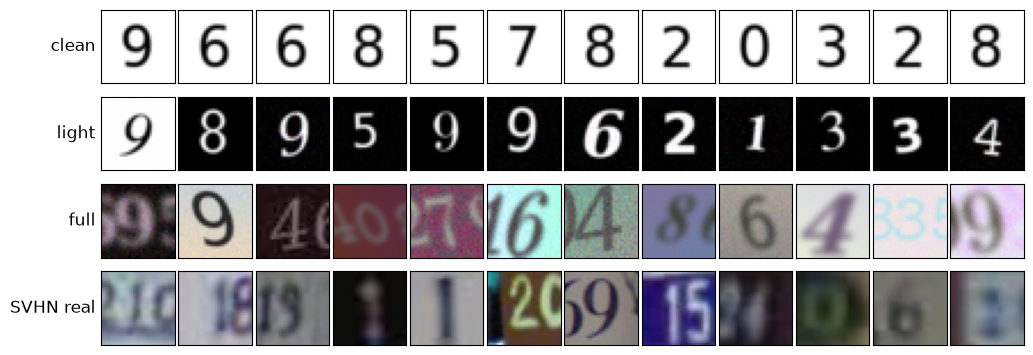

In [7]:
def show_grid(rows, titles, n=12, scale=1.6, path=None):
    fig, axes = plt.subplots(len(rows), n, figsize=(n * scale * 0.62, len(rows) * scale * 0.7), squeeze=False)
    for r, (X, title) in enumerate(zip(rows, titles)):
        for c in range(n):
            ax = axes[r, c]; ax.imshow(X[c]); ax.set_xticks([]); ax.set_yticks([])
            if c == 0:
                ax.set_ylabel(title, fontsize=12, rotation=0, ha="right", va="center")
    plt.subplots_adjust(wspace=0.05, hspace=0.05)
    if path:
        plt.savefig(path, dpi=110, bbox_inches="tight")
    plt.show()

demo = {lv: make_synth(lv, 12, seed=7)[0] for lv in ["clean", "light", "full"]}
show_grid([demo["clean"], demo["light"], demo["full"], Xte[:12]], ["clean", "light", "full", "SVHN real"], path=ART / "levels.png")

## 13. Domain randomization: синтетическая валидация против реального test

Обучим одну и ту же CNN на трёх уровнях синтетики и для сравнения — на реальных данных того же объёма (это потолок, «train on target» в терминах DANN). У каждой синтетической модели две оценки: на синтетической валидации своего уровня и на real test.

Ожидание из раздела 7 теории: синтетическая валидация измеряет ошибку на исходном распределении $\varepsilon_S$, а нам нужна $\varepsilon_T$. Чем уже пространство сцен, тем легче задача на синтетике и тем больше разрыв.

In [8]:
N_SMALL = S["n_syn"] // 2
SYN = {}
for lv, n in [("clean", N_SMALL), ("light", N_SMALL), ("full", S["n_syn"])]:
    t0 = time.time()
    SYN[lv] = make_synth(lv, n, seed={"clean": 11, "light": 12, "full": 13}[lv])
    Xv, yv, _ = make_synth(lv, 1000, seed=100 + len(SYN))
    m = train_cnn([(SYN[lv][0], SYN[lv][1], 1.0)], steps_for(n))
    evaluate(f"synth {lv} ({n // 1000}k)", m, Xv, yv, note=f"{time.time() - t0:.0f} s")
    if lv == "full":
        M_FULL = m
t0 = time.time()
REF_IDX = POOL_IDX[:min(S["n_syn"], 40000)]
M_REAL = train_cnn([(Xtr_all[REF_IDX], ytr_all[REF_IDX], 1.0)], steps_for(len(REF_IDX)))
evaluate(f"real ({len(REF_IDX) // 1000}k), потолок", M_REAL, note=f"{time.time() - t0:.0f} s")

synth clean (10k)            real test 0.068 [0.061, 0.076]  real val 0.085  synth val 1.000


synth light (10k)            real test 0.151 [0.141, 0.160]  real val 0.110  synth val 1.000


synth full (20k)             real test 0.626 [0.613, 0.639]  real val 0.513  synth val 0.963


real (20k), потолок          real test 0.833 [0.823, 0.844]  real val 0.834


{'real_test': np.float64(0.8332),
 'ci_lo': np.float64(0.822595),
 'ci_hi': np.float64(0.844),
 'real_val': np.float64(0.834),
 'note': '57 s'}

Что видно. Синтетическая валидация у `clean` и `light` равна 1,000, а на real test эти модели дают 0,068 и 0,151 — около уровня случайного угадывания (10%) и ниже, чем всегда отвечать самым частым классом (единица, 19,5% test). У `full` синтетическая валидация ниже (0,963), а real test — 0,626 [0,613; 0,639]. Ранжирование по синтетической валидации обратно ранжированию по real test: выбрав модель по ней, мы взяли бы худшую. Это главный аргумент против выбора моделей, порогов и рецептов генерации по синтетической валидации: её значение растёт, когда пространство сцен сужается, а реальная точность при этом падает.

Domain randomization `full` даёт основной скачок: та же архитектура и сопоставимый объём данных, но разнообразие цветов, фонов, соседних цифр, размытия и сжатия поднимает точность на real test с 0,151 до 0,626. До потолка — модели на 20 тысячах реальных цифр, 0,833 [0,823; 0,844] — остаётся около 21 пункта; его мы будем закрывать в разделах 14–22.

Посмотрим, на каких классах модель `full` ошибается чаще всего на реальных данных.

In [9]:
p_full = predict(M_FULL, Xte).argmax(1)
cm = pd.crosstab(pd.Series(yte, name="истина"), pd.Series(p_full, name="предсказание"))
per_class = (np.diag(cm.reindex(index=range(10), columns=range(10), fill_value=0).values) / np.bincount(yte, minlength=10)).round(3)
print("точность по классам (synth full):", dict(enumerate(per_class)))
pairs = [(i, j, cm.loc[i, j]) for i in cm.index for j in cm.columns if i != j]
print("частые путаницы (истина → предсказание, число):", sorted(pairs, key=lambda t: -t[2])[:6])

точность по классам (synth full): {0: np.float64(0.701), 1: np.float64(0.795), 2: np.float64(0.494), 3: np.float64(0.424), 4: np.float64(0.743), 5: np.float64(0.738), 6: np.float64(0.59), 7: np.float64(0.765), 8: np.float64(0.431), 9: np.float64(0.474)}
частые путаницы (истина → предсказание, число): [(2, 1, np.int64(173)), (3, 1, np.int64(145)), (4, 1, np.int64(94)), (1, 7, np.int64(87)), (2, 4, np.int64(85)), (7, 1, np.int64(61))]


## 14. Compositing: синтетическая цифра на реальном фоне

Второй источник синтетики — вставка объекта в реальную фотографию. Объект у нас программный (глиф шрифта), а фон берём из реальных фотографий CIFAR-10 ([Krizhevsky, 2009](https://www.cs.toronto.edu/~kriz/cifar.html)): случайный фрагмент 16×16 увеличивается до размера холста. Это та же идея, что в SynthText и Cut, Paste and Learn: реальная статистика фона плюс точная разметка объекта.

Сравниваем `full` (фоны только процедурные) и `full + photo` (в 40% примеров фон — фрагмент фотографии) при одинаковом объёме.

фоновых фрагментов: 2000


synth full + photo (20k)     real test 0.615 [0.601, 0.628]  real val 0.497  synth val 0.877


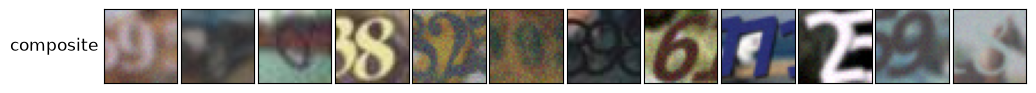

In [10]:
cifar = pq.read_table(hf_hub_download("uoft-cs/cifar10", "plain_text/test-00000-of-00001.parquet", repo_type="dataset")).to_pandas()
img_col = [c for c in cifar.columns if "im" in c][0]
g = np.random.default_rng(3)
TEXTURES = []
for b in cifar[img_col].iloc[:2000]:
    im = Image.open(io.BytesIO(b["bytes"])).convert("RGB")
    x, y0 = g.integers(0, 17, 2)
    TEXTURES.append(im.crop((int(x), int(y0), int(x) + 16, int(y0) + 16)))
print("фоновых фрагментов:", len(TEXTURES))
t0 = time.time()
SYN["photo"] = make_synth("full", S["n_syn"], seed=14, textures=TEXTURES)
Xv, yv, _ = make_synth("full", 1000, seed=114, textures=TEXTURES)
M_PHOTO = train_cnn([(SYN["photo"][0], SYN["photo"][1], 1.0)], steps_for(S["n_syn"]))
evaluate(f"synth full + photo ({S['n_syn'] // 1000}k)", M_PHOTO, Xv, yv, note=f"{time.time() - t0:.0f} s")
Xc = make_synth("full", 400, seed=7, textures=TEXTURES)
show_grid([Xc[0][[i for i, s in enumerate(Xc[2]) if s["bg"] == "photo"][:12]]], ["composite"], path=ART / "composite.png")

Что видно. Ожидание было такое: реальные фоны добавят структурированный «мусор» (края, текстуры, перепады яркости), похожий на фон SVHN; в DANN именно структурированный фон SVHN назван главным отличием Syn Numbers от реальных данных ([Ganin et al., 2016](https://arxiv.org/pdf/1505.07818)). В нашем прогоне этого не произошло: `full + photo` даёт 0,615 [0,601; 0,628] против 0,626 [0,613; 0,639] у `full`, интервалы перекрываются, то есть разницы мы не обнаружили. Возможные причины: фоны из CIFAR-10 размыты при уменьшении до 16×16 и мало похожи на стены и таблички, процедурные фоны `full` уже достаточно разнообразны, а 20 тысяч примеров — мало, чтобы новый источник разнообразия окупился. Это полезный отрицательный результат: правдоподобная гипотеза о реалистичности проверяется на real val и real test, а не принимается по умолчанию. Дальше `M_PHOTO` используется как основная модель «только синтетика», потому что именно её данные прошли весь конвейер с compositing.

## 15. Спецификации от LLM: схема, валидация, разнообразие

### 15.1. Зачем LLM на этом шаге

Сэмплер из раздела 12 покрывает пространство параметров равномерно, но ничего не знает о мире: он не знает, что номера на кирпичных стенах чаще белые, а таблички ночью подсвечены. LLM знает много таких семантических связей и может предлагать спецификации «по контексту»: «старый деревенский дом», «магазин ночью». Это идея LayoutGPT, LMD и CoSyn из раздела 3.2: языковая модель пишет структурированное описание сцены, а изображение строит отдельный исполнитель.

Контракт между LLM и рендерером — JSON Schema. LLM генерирует семантические поля (цвет, материал фона, освещение, размытие, число соседних цифр, наклон). «Компилятор» переводит их в параметры рендерера, а всё, что LLM не задаёт (точный оттенок, сдвиг, шум, JPEG), досэмплирует сам с seed записи.

В качестве LLM берём Qwen2.5-0.5B-Instruct ([Hugging Face](https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct)): она помещается в CPU и при этом достаточно слаба, чтобы на ней были видны все типичные проблемы. Модели крупнее ошибаются реже, но ошибки тех же типов остаются, поэтому валидация нужна всегда.

In [11]:
import jsonschema
from transformers import AutoTokenizer, AutoModelForCausalLM

COLORS = {"white": (235, 235, 230), "black": (25, 25, 28), "gray": (128, 128, 128), "red": (170, 40, 35), "blue": (40, 60, 150),
          "yellow": (220, 190, 60), "green": (40, 120, 60), "brown": (110, 75, 45)}
BACKGROUNDS = ["plain wall", "painted metal", "brick", "wood", "glass", "plastic sign"]
LIGHTING = ["daylight", "overcast", "night", "backlit", "shadow"]
SCHEMA = {
    "type": "object", "additionalProperties": False,
    "required": ["digit", "font_style", "bold", "italic", "text_color", "background", "background_color", "lighting", "blur", "neighbors", "tilt_degrees"],
    "properties": {
        "digit": {"type": "integer", "minimum": 0, "maximum": 9},
        "font_style": {"enum": ["sans", "serif", "mono"]}, "bold": {"type": "boolean"}, "italic": {"type": "boolean"},
        "text_color": {"enum": list(COLORS)}, "background": {"enum": BACKGROUNDS}, "background_color": {"enum": list(COLORS)},
        "lighting": {"enum": LIGHTING}, "blur": {"enum": ["none", "slight", "strong"]},
        "neighbors": {"type": "integer", "minimum": 0, "maximum": 2}, "tilt_degrees": {"type": "number", "minimum": -15, "maximum": 15}}}
EXAMPLE = {"digit": 3, "font_style": "serif", "bold": False, "italic": False, "text_color": "black", "background": "painted metal",
           "background_color": "white", "lighting": "overcast", "blur": "slight", "neighbors": 1, "tilt_degrees": 4}
CONTEXTS = ["a modern apartment building", "an old village house", "a shop at night", "a rainy day in a city", "a sunny suburban street",
            "an office door", "a hotel entrance", "a garage in winter", "a school building", "a farm gate", "a seaside cafe", "a factory gate"]
SYSTEM = "You write scene specifications for a renderer of street house-number photos. Output only one JSON object that follows the schema."
def describe(v):
    if "enum" in v:
        return "one of " + " | ".join(v["enum"])
    if "minimum" in v:
        return f"{v['type']} from {v['minimum']} to {v['maximum']}"
    return v["type"]
USER = ("Fields (each value is a single string, number or boolean, never a list):\n" + "\n".join(f"- {k}: {describe(v)}" for k, v in SCHEMA["properties"].items())
        + "\nExample: " + json.dumps(EXAMPLE) + "\nContext: {ctx}\nWrite one new specification for this context.")
print(USER.replace("{ctx}", CONTEXTS[0]))

Fields (each value is a single string, number or boolean, never a list):
- digit: integer from 0 to 9
- font_style: one of sans | serif | mono
- bold: boolean
- italic: boolean
- text_color: one of white | black | gray | red | blue | yellow | green | brown
- background: one of plain wall | painted metal | brick | wood | glass | plastic sign
- background_color: one of white | black | gray | red | blue | yellow | green | brown
- lighting: one of daylight | overcast | night | backlit | shadow
- blur: one of none | slight | strong
- neighbors: integer from 0 to 2
- tilt_degrees: number from -15 to 15
Example: {"digit": 3, "font_style": "serif", "bold": false, "italic": false, "text_color": "black", "background": "painted metal", "background_color": "white", "lighting": "overcast", "blur": "slight", "neighbors": 1, "tilt_degrees": 4}
Context: a modern apartment building
Write one new specification for this context.


### 15.2. Генерация и разбор ответа

Генерируем по одной спецификации на запрос с сэмплированием ($T = 0{,}9$, top-p 0,95), батчами. Разбор в четыре шага: извлечь первый JSON-объект из текста; проверить по схеме; если есть ошибки — детерминированный ремонт формата (список из одного значения → значение, синонимы вроде `grey` → `gray`, обрезка числа до допустимого диапазона, удаление лишних полей) и повторная проверка; если и это не помогло — один повтор запроса с сообщением валидатора (как в лекции 7). Ремонт рассчитан на ошибки формы; обрезка числа до диапазона уже немного меняет содержание, поэтому каждое исправление записывается отдельно и его можно запретить. Для каждой попытки сохраняем сырой ответ, параметры генерации, ошибки и список исправлений: это часть provenance. Валидность считаем отдельно до ремонта и после него, чтобы ремонт не маскировал качество модели.

In [12]:
LLM_ID = "Qwen/Qwen2.5-0.5B-Instruct"
llm_tok = AutoTokenizer.from_pretrained(LLM_ID); llm_tok.padding_side = "left"
llm = AutoModelForCausalLM.from_pretrained(LLM_ID, dtype=torch.float16 if HAS_GPU else torch.float32).to(DEVICE).eval()
try:
    LLM_REV = model_info(LLM_ID).sha
except Exception:
    LLM_REV = "unknown"
GEN_KW = dict(max_new_tokens=140, do_sample=True, temperature=0.9, top_p=0.95)

def extract_json(text):
    m = re.search(r"\{.*?\}", text, re.S)
    if not m:
        return None, "no JSON object found"
    try:
        return json.loads(m.group(0)), None
    except json.JSONDecodeError as e:
        return None, f"JSON decode error: {e.msg}"

def validate(obj):
    errs = sorted(jsonschema.Draft7Validator(SCHEMA).iter_errors(obj), key=lambda e: list(e.path))
    return [f"{'/'.join(map(str, e.path)) or '(root)'}: {e.message[:120]}" for e in errs]

SYNONYMS = {"grey": "gray", "sans-serif": "sans", "sans serif": "sans", "monospace": "mono", "monospaced": "mono", "metal": "painted metal",
            "wall": "plain wall", "sign": "plastic sign", "day": "daylight", "sunny": "daylight", "cloudy": "overcast", "dark": "night",
            "shade": "shadow", "shadowed": "shadow", "slightly": "slight", "light": "slight", "no": "none", "heavy": "strong"}

def repair(obj):
    """Детерминированный ремонт типичных ошибок формата. Каждое исправление записывается в список notes (provenance)."""
    if not isinstance(obj, dict):
        return obj, []
    out, notes = {}, []
    for k, v in obj.items():
        if k not in SCHEMA["properties"]:
            notes.append(f"drop extra field {k}"); continue
        prop = SCHEMA["properties"][k]
        if isinstance(v, list) and v:
            v = v[0]; notes.append(f"{k}: list -> first element")
        if isinstance(v, str) and "enum" in prop:
            w = SYNONYMS.get(v.strip().lower(), v.strip().lower())
            if w != v:
                notes.append(f"{k}: {v!r} -> {w!r}")
            v = w
        if prop.get("type") in ("integer", "number") and isinstance(v, (int, float)) and not isinstance(v, bool):
            w = min(max(v, prop["minimum"]), prop["maximum"])
            w = int(round(w)) if prop["type"] == "integer" else w
            if w != v:
                notes.append(f"{k}: {v} -> {w} (clip)")
            v = w
        out[k] = v
    return out, notes

def parse(text):
    """Разбор ответа: JSON → схема; при ошибках схемы — ремонт и повторная проверка."""
    obj, err = extract_json(text)
    if err:
        return None, [err], [], [err]
    errs = validate(obj)
    if not errs:
        return obj, [], [], []
    fixed, notes = repair(obj)
    errs2 = validate(fixed)
    return (fixed if not errs2 else None), errs, notes, errs2

@torch.no_grad()
def llm_generate(user_msgs, seed, bs=8):
    outs = []
    for i in range(0, len(user_msgs), bs):
        texts = [llm_tok.apply_chat_template([{"role": "system", "content": SYSTEM}, {"role": "user", "content": u}], tokenize=False,
                                             add_generation_prompt=True) for u in user_msgs[i:i + bs]]
        enc = llm_tok(texts, return_tensors="pt", padding=True).to(DEVICE)
        torch.manual_seed(seed + i)
        out = llm.generate(**enc, **GEN_KW, pad_token_id=llm_tok.eos_token_id)
        outs += [llm_tok.decode(o[enc.input_ids.shape[1]:], skip_special_tokens=True) for o in out]
    return outs

t0 = time.time()
ctx_list = [CONTEXTS[i % len(CONTEXTS)] for i in range(S["n_llm"])]
raw = llm_generate([USER.replace("{ctx}", c) for c in ctx_list], seed=SEED)
LLM_RECS = []
for i, (c, r) in enumerate(zip(ctx_list, raw)):
    spec, errs, notes, errs2 = parse(r)
    LLM_RECS.append({"i": i, "context": c, "attempts": [{"raw": r, "errors": errs, "repairs": notes, "errors_after_repair": errs2}], "spec": spec})
raw_ok = sum(not r["attempts"][0]["errors"] for r in LLM_RECS)
first_ok = sum(r["spec"] is not None for r in LLM_RECS)
retry = [r for r in LLM_RECS if r["spec"] is None]
fix_msgs = [USER.replace("{ctx}", r["context"]) + "\nYour previous answer was invalid: " + "; ".join(r["attempts"][0]["errors_after_repair"][:3])
            + "\nReturn a corrected JSON object." for r in retry]
for r, out in zip(retry, llm_generate(fix_msgs, seed=SEED + 1000) if retry else []):
    spec, errs, notes, errs2 = parse(out)
    r["attempts"].append({"raw": out, "errors": errs, "repairs": notes, "errors_after_repair": errs2}); r["spec"] = spec
second_ok = sum(r["spec"] is not None for r in LLM_RECS)
n_rep = sum(bool(r["attempts"][-1]["repairs"]) for r in LLM_RECS if r["spec"] is not None)
print(f"{S['n_llm']} запросов за {time.time() - t0:.0f} с\n"
      f"  валидно как есть, первая попытка:  {raw_ok:3d} ({raw_ok / S['n_llm']:.0%})\n"
      f"  + после ремонта формата:           {first_ok:3d} ({first_ok / S['n_llm']:.0%})\n"
      f"  + после повтора запроса:           {second_ok:3d} ({second_ok / S['n_llm']:.0%}); из принятых с ремонтом: {n_rep}")
err_types = Counter(re.sub(r"'[^']*'|\d+(\.\d+)?", "…", e.split(": ", 1)[-1])[:60] for r in LLM_RECS for e in r["attempts"][0]["errors"])
print("частые ошибки первой попытки:"); [print(f"  {n:3d} × {e}") for e, n in err_types.most_common(6)]
bad = next((r["attempts"][0] for r in LLM_RECS if r["attempts"][0]["errors"]), None)
if bad:
    print("пример невалидного ответа:", repr(bad["raw"])[:400])
    print("ремонт:", bad["repairs"][:6], "| ошибки после ремонта:", bad["errors_after_repair"][:3])
rep_types = Counter(re.sub(r"'[^']*'|-?\d+(\.\d+)?", "…", n) for r in LLM_RECS for a in r["attempts"] for n in a["repairs"])
print("частые исправления:", rep_types.most_common(6))

48 запросов за 270 с
  валидно как есть, первая попытка:   16 (33%)
  + после ремонта формата:            40 (83%)
  + после повтора запроса:            45 (94%); из принятых с ремонтом: 27
частые ошибки первой попытки:
   25 × … is greater than the maximum of …
   11 × … is a required property
    5 × -… is less than the minimum of -…
    4 × … is not one of […, …, …, …, …, …, …, …]
    4 × None is not of type …
    3 × … is not one of […, …, …]
пример невалидного ответа: '```json\n{\n  "digit": 6,\n  "font_style": "sans",\n  "bold": true,\n  "italic": false,\n  "text_color": "blue",\n  "background": "brick",\n  "background_color": "gray",\n  "lighting": "night",\n  "blur": "strong",\n  "neighbors": 1,\n  "tilt_degrees": 20\n}\n```'
ремонт: ['tilt_degrees: 20 -> 15 (clip)'] | ошибки после ремонта: []
частые исправления: [('tilt_degrees: … -> … (clip)', 26), ('neighbors: … -> … (clip)', 6), ('font_style: … -> …', 5), ('background_color: … -> …', 2), ('drop extra field image_aspect_rati

### 15.3. Разнообразие: LLM против равномерного сэмплера

Валидность — только первое требование. Второе — покрытие пространства сцен. Сравним распределения полей у валидных LLM-спецификаций с равномерным сэмплером по тем же полям. Мера — нормированная энтропия $H/\log K$ (1 — равномерно, 0 — всегда одно значение), а также число точных повторов спецификаций.

In [13]:
VALID = [r for r in LLM_RECS if r["spec"] is not None]
fields = ["digit", "font_style", "text_color", "background", "background_color", "lighting", "blur", "neighbors"]
def norm_entropy(values, k):
    p = np.array(list(Counter(values).values()), dtype=float); p /= p.sum()
    return float(-(p * np.log(p)).sum() / np.log(k))
K = {"digit": 10, "font_style": 3, "text_color": 8, "background": 6, "background_color": 8, "lighting": 5, "blur": 3, "neighbors": 3}
rows = []
for f in fields:
    vals = [r["spec"][f] for r in VALID]
    top, cnt = Counter(vals).most_common(1)[0] if vals else ("-", 0)
    rows.append({"поле": f, "H/logK (LLM)": round(norm_entropy(vals, K[f]), 2) if vals else None,
                 "самое частое значение": f"{top} ({cnt / max(len(vals), 1):.0%})", "H/logK (uniform)": 1.0})
print(pd.DataFrame(rows).to_string(index=False))
same_color = sum(r["spec"]["text_color"] == r["spec"]["background_color"] for r in VALID)
dups = len(VALID) - len({canon(r["spec"]) for r in VALID})
print(f"\nвалидных: {len(VALID)} | точных повторов спецификации: {dups} | текст того же цвета, что фон: {same_color}")

            поле  H/logK (LLM) самое частое значение  H/logK (uniform)
           digit          0.72               7 (31%)               1.0
      font_style          0.48            sans (78%)               1.0
      text_color          0.81            gray (33%)               1.0
      background          0.89      plain wall (29%)               1.0
background_color          0.68            gray (40%)               1.0
        lighting          0.36           night (73%)               1.0
            blur          0.53          strong (73%)               1.0
       neighbors          0.87               2 (49%)               1.0

валидных: 45 | точных повторов спецификации: 0 | текст того же цвета, что фон: 5


Что видно. Как есть схему прошла только треть ответов (16 из 48); ремонт формата поднял долю до 83%, повтор запроса — до 94%. Самая частая ошибка — число вне диапазона (наклон 20° при допустимых ±15°, три соседние цифры при максимуме два), на втором месте пропущенные поля. Ремонт понадобился 27 из 45 принятых спецификаций, поэтому без записи исправлений в provenance нельзя было бы понять, что именно предложила модель.

Валидные ответы распределены очень неравномерно: `night` в 73% спецификаций, `strong` blur в 73%, шрифт `sans` в 78%; нормированная энтропия освещения 0,36 против 1,0 у равномерного сэмплера. Цифры тоже неравномерны: семёрка в 31% ответов, а это прямой сдвиг баланса классов, если брать метку из спецификации. Схема пропустила 5 спецификаций с текстом того же цвета, что фон: формально валидно, а цифры на изображении не видно.

Отсюда практическое правило: LLM отвечает за семантику и «длинный хвост» контекстов, а за покрытие отвечает код. Баланс классов и диапазоны числовых параметров задаются квотами и сэмплером, а не просьбой «сделай разнообразно». Ниже «компилятор» с этим разделением: цифру он берёт из квоты (по кругу 0–9), семантические поля — у LLM, остальное досэмплирует.

примеры (контекст → цифра): [('a modern apartment bui', 0), ('an old village house', 1), ('a shop at night', 2), ('a rainy day in a city', 3)]


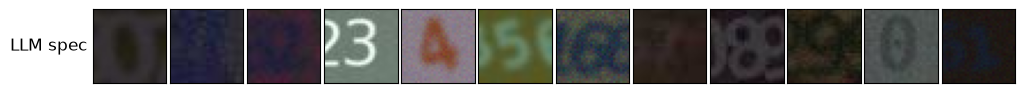

In [14]:
FONT_BY_STYLE = {("sans", False, False): "DejaVuSans.ttf", ("sans", True, False): "DejaVuSans-Bold.ttf", ("sans", False, True): "DejaVuSans-Oblique.ttf",
                 ("sans", True, True): "DejaVuSans-BoldOblique.ttf", ("serif", False, False): "DejaVuSerif.ttf", ("serif", True, False): "DejaVuSerif-Bold.ttf",
                 ("serif", False, True): "DejaVuSerif-Italic.ttf", ("serif", True, True): "DejaVuSerif-BoldItalic.ttf", ("mono", False, False): "DejaVuSansMono.ttf",
                 ("mono", True, False): "DejaVuSansMono-Bold.ttf", ("mono", False, True): "DejaVuSansMono-Oblique.ttf", ("mono", True, True): "DejaVuSansMono-BoldOblique.ttf"}
BG_KIND = {"plain wall": "flat", "painted metal": "gradient", "brick": "noise", "wood": "noise", "glass": "gradient", "plastic sign": "flat"}

def compile_spec(sem, seed, digit=None):
    """Семантическая спецификация LLM → параметры рендерера. Цифра — из квоты (если задана), остальное досэмплируется."""
    rng = np.random.default_rng(seed)
    jit = lambda c, s=18: [int(np.clip(v + rng.normal(0, s), 0, 255)) for v in c]
    light = sem["lighting"]
    fg, bg = jit(COLORS[sem["text_color"]]), jit(COLORS[sem["background_color"]])
    if light == "night":
        fg, bg = [int(v * 0.45) for v in fg], [int(v * 0.35) for v in bg]
    contrast = {"daylight": 1.0, "overcast": 0.8, "night": 0.7, "backlit": 0.5, "shadow": 0.85}[light]
    nb = [dict(digit=int(rng.integers(0, 10)), dx=float(side * rng.uniform(0.42, 0.62))) for side in [-1, 1][:int(sem["neighbors"])]]
    return {"digit": int(sem["digit"] if digit is None else digit), "seed": int(seed), "level": "llm",
            "font": FONT_BY_STYLE[(sem["font_style"], bool(sem["bold"]), bool(sem["italic"]))], "fg_rgb": fg, "bg": BG_KIND[sem["background"]],
            "bg_rgb": bg, "bg_rgb2": jit(bg, 40), "bg_tex": 0, "scale": float(rng.uniform(0.8, 1.35)), "rotation": float(sem["tilt_degrees"]),
            "shear": float(rng.uniform(-0.15, 0.15)), "dx": float(rng.uniform(-0.05, 0.05)), "dy": float(rng.uniform(-0.05, 0.05)), "neighbors": nb,
            "blur": {"none": 0.0, "slight": 0.6, "strong": 1.4}[sem["blur"]], "noise": float(rng.uniform(2, 10)), "contrast": contrast,
            "jpeg": int(rng.choice([0, int(rng.integers(40, 90))])), "shadow": int(light == "shadow")}

def sample_sem(rng):
    """Равномерный сэмплер семантических полей — запасной источник и база для сравнения."""
    pick = lambda f: str(rng.choice(SCHEMA["properties"][f]["enum"]))
    return {"digit": int(rng.integers(0, 10)), "font_style": pick("font_style"), "bold": bool(rng.integers(0, 2)), "italic": bool(rng.integers(0, 2)),
            "text_color": pick("text_color"), "background": pick("background"), "background_color": pick("background_color"),
            "lighting": pick("lighting"), "blur": pick("blur"), "neighbors": int(rng.integers(0, 3)), "tilt_degrees": float(rng.uniform(-15, 15))}

LLM_SPECS = [compile_spec(r["spec"], seed=50_000_000 + k, digit=k % 10) for k, r in enumerate(VALID)]
for r, s in zip(VALID, LLM_SPECS):
    r["render_spec"] = s
llm_imgs = [np.array(render(s)) for s in LLM_SPECS]
print("примеры (контекст → цифра):", [(r["context"][:22], s["digit"]) for r, s in zip(VALID[:4], LLM_SPECS[:4])])
if len(llm_imgs) >= 12:
    show_grid([np.stack(llm_imgs[:12])], ["LLM spec"], path=ART / "llm_specs.png")
del llm; gc.collect()
if HAS_GPU:
    torch.cuda.empty_cache()

## 16. Генеративная модель: метка из промпта не равна содержимому

Третий источник синтетики — text-to-image модель. Берём SD-Turbo: это дистиллированная методом ADD версия Stable Diffusion 2.1, которая генерирует изображение за один шаг без classifier-free guidance (`guidance_scale=0.0`), предпочтительное разрешение 512×512 ([модель на Hugging Face](https://huggingface.co/stabilityai/sd-turbo), [Sauer et al., 2023](https://arxiv.org/abs/2311.17042)). На CPU один шаг при 384×384 занимает несколько десятков секунд, поэтому в `FAST_DEV_RUN` генерируем всего несколько изображений; на T4 — 64 при 512×512.

Промпт строится из той же семантической спецификации LLM, что и в разделе 15, — так конвейер «пространство сцен → спецификация → изображение» один и тот же для рендерера и для генеративной модели. Цифра снова берётся из квоты. В provenance пишутся промпт, seed, модель, ревизия, число шагов, guidance и разрешение.

/home/user/cvtest/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


/home/user/cvtest/.venv/lib/python3.12/site-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
/home/user/cvtest/.venv/lib/python3.12/site-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)



You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


загрузка 4 с
источник семантики: Counter({'llm': 8})


8 изображений за 219 с (27.4 с на изображение)


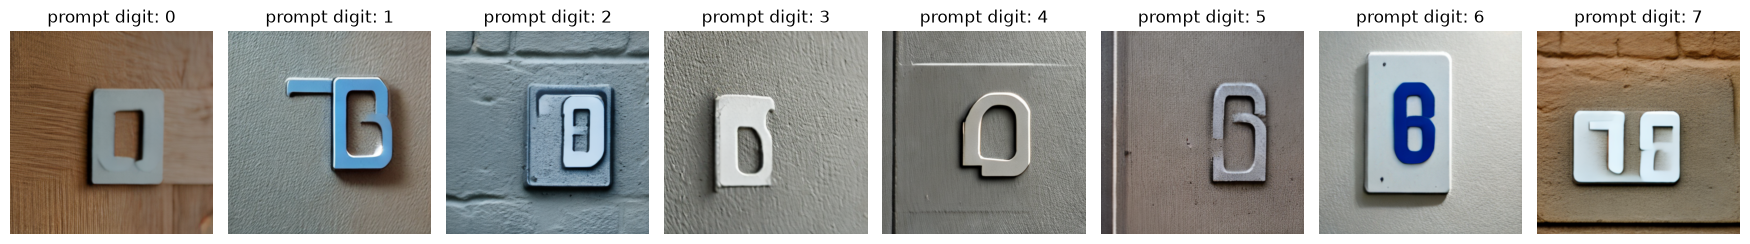

{
 "source": "sd-turbo",
 "label": 0,
 "image_sha256": "2f8ae1a82496fb96e508776a5f0f43b1820f1ec78e3961e2f190563196a1bf5f",
 "dhash": "bb3323232323333a",
 "prompt": "close-up photo of a house number sign, the single digit 0 in gray on a brown wood, night light, the digit fills the frame",
 "seed": 90000,
 "model": "stabilityai/sd-turbo",
 "revision": "b261bac6fd2cf515557d5d0707481eafa0485ec2",
 "crop": "center 50%",
 "sem_source": "llm",
 "num_inference_steps": 1,
 "guidance_scale": 0.0,
 "height": 384,
 "width": 384,
 "id": "sd-turbo-2f8ae1a82496"
}


In [15]:
from diffusers import AutoPipelineForText2Image
GEN_ID = "stabilityai/sd-turbo"
try:
    GEN_REV = model_info(GEN_ID).sha
except Exception:
    GEN_REV = "unknown"
t0 = time.time()
pipe = AutoPipelineForText2Image.from_pretrained(GEN_ID, torch_dtype=torch.float16, variant="fp16")
pipe = pipe.to(DEVICE) if HAS_GPU else pipe.to(torch.bfloat16)
pipe.set_progress_bar_config(disable=True)
print(f"загрузка {time.time() - t0:.0f} с")

def gen_prompt(sem, digit):
    return (f"close-up photo of a house number sign, the single digit {digit} in {sem['text_color']} on a "
            f"{sem['background_color']} {sem['background']}, {sem['lighting']} light, the digit fills the frame")

# семантика — из валидных LLM-спецификаций; если их меньше n_gen, добираем равномерным сэмплером и отмечаем это в provenance
_rng = np.random.default_rng(SEED + 7)
GEN_SEMS = [(r["spec"], "llm") for r in VALID[:S["n_gen"]]]
GEN_SEMS += [(sample_sem(_rng), "uniform") for _ in range(S["n_gen"] - len(GEN_SEMS))]
print("источник семантики:", Counter(src for _, src in GEN_SEMS))
GEN = []
t0 = time.time()
for k, (sem, sem_src) in enumerate(GEN_SEMS):
    d = k % 10; seed = 90_000 + k
    prompt = gen_prompt(sem, d)
    gen_kw = dict(num_inference_steps=1, guidance_scale=0.0, height=S["gen_res"], width=S["gen_res"])
    big = pipe(prompt=prompt, generator=torch.Generator().manual_seed(seed), **gen_kw).images[0]
    w = big.width; c = int(w * 0.25)
    small = big.crop((c, c, w - c, w - c)).resize((32, 32), Image.LANCZOS)
    GEN.append({"big": big, "img": np.array(small), "label": d,
                "rec": provenance("sd-turbo", small, label=d, prompt=prompt, seed=seed, model=GEN_ID, revision=GEN_REV,
                                  crop="center 50%", sem_source=sem_src, **gen_kw)})
print(f"{len(GEN)} изображений за {time.time() - t0:.0f} с ({(time.time() - t0) / max(len(GEN), 1):.1f} с на изображение)")
fig, axes = plt.subplots(1, len(GEN[:8]), figsize=(2.2 * len(GEN[:8]), 2.6), squeeze=False)
for ax, gk in zip(axes[0], GEN[:8]):
    ax.imshow(gk["big"]); ax.set_title(f"prompt digit: {gk['label']}", fontsize=12); ax.axis("off")
plt.tight_layout(); plt.savefig(ART / "sd_turbo.png", dpi=90, bbox_inches="tight"); plt.show()
print(json.dumps(GEN[0]["rec"], ensure_ascii=False, indent=1))
del pipe; gc.collect()
if HAS_GPU:
    torch.cuda.empty_cache()

Что видно. Модель хорошо воспроизводит «стиль» запроса: табличку, материал стены, фактуру. Но нужная цифра однозначно не читается ни на одном из 8 изображений: вместо «1» и «7» нарисовано что-то вроде «7B», вместо «2» и «6» — знаки, похожие на «8» или «B», вместо «5» — «G», вместо «0», «3» и «4» — знаки, похожие на «D» или «O» (для «0» это ещё можно счесть приближением). Текст на изображениях — известная слабость диффузионных моделей, особенно дистиллированных до одного шага, а для нашей задачи это главная часть содержания. Если поставить таким изображениям метку из промпта, в датасет попадёт шум разметки, причём систематический: модель ошибается не случайно, а одинаковым образом на похожих промптах.

Это и есть причина, по которой в конвейере после генерации стоит проверка. У рендерера метка верна по построению и ошибки бывают только из-за багов; у генеративной модели метка — это гипотеза, которую нужно подтвердить.

## 17. Проверки: правила рендерера и VLM

### 17.1. Набор кандидатов с известными дефектами

Чтобы измерить качество проверок, нужен набор, где мы знаем правильный ответ. Соберём кандидатов из трёх источников и в часть программных примеров внесём дефекты трёх типов, которые встречаются в реальных генераторах:

- `label_bug` — рендерер нарисовал не ту цифру, что в спецификации (ошибка в таблице глифов, перепутанные поля): метка неверна, изображение выглядит нормально;
- `off_frame` — целевая цифра ушла за край, а в центр попала соседняя (ошибка в формуле сдвига): метка неверна для того, что видно;
- `low_contrast` — цвет текста почти совпадает с цветом фона: цифры не видно.

Для LLM-спецификаций дефект по построению — «текст почти того же цвета, что фон» (разность яркостей меньше 20). Для генеративных изображений истинная метка неизвестна: их мы проверяем, но в метрики качества проверок не включаем.

In [16]:
rng = np.random.default_rng(21)
FAULTS = ["none"] * 17 + ["label_bug", "off_frame", "low_contrast"]            # ≈15% дефектов
CAND = []
n_render = S["n_check"] - len(LLM_SPECS) - len(GEN)
for i in range(n_render):
    spec = sample_spec(rng, "full", 70_000_000 + i, n_tex=len(TEXTURES))
    fault = str(rng.choice(FAULTS)); drawn = dict(spec)
    if fault == "label_bug":
        drawn["digit"] = int((spec["digit"] + rng.integers(1, 10)) % 10)
    elif fault == "off_frame":
        drawn["dx"] = float(rng.choice([-1, 1]) * rng.uniform(0.42, 0.5))
        drawn["neighbors"] = [dict(digit=int((spec["digit"] + rng.integers(1, 10)) % 10), dx=-np.sign(drawn["dx"]) * 0.45)]
    elif fault == "low_contrast":
        drawn["fg_rgb"] = [int(np.clip(v + rng.normal(0, 4), 0, 255)) for v in spec["bg_rgb"]]
    im, mask = render(drawn, TEXTURES, return_mask=True)
    CAND.append({"img": np.array(im), "mask": mask, "label": spec["digit"], "source": "composite" if spec["bg"] == "photo" else "render",
                 "fault": fault, "spec": spec, "rec": provenance("render", im, spec, fault_injected=fault)})
for s in LLM_SPECS:
    im, mask = render(s, return_mask=True)
    bad = abs(lum(s["fg_rgb"]) - lum(s["bg_rgb"])) < 20
    CAND.append({"img": np.array(im), "mask": mask, "label": s["digit"], "source": "llm", "fault": "same_color" if bad else "none",
                 "spec": s, "rec": provenance("llm+render", im, s, llm=LLM_ID, llm_revision=LLM_REV)})
for gk in GEN:
    CAND.append({"img": gk["img"], "mask": None, "label": gk["label"], "source": "sd-turbo", "fault": None, "spec": None, "rec": gk["rec"]})
cdf = pd.DataFrame([{"source": c["source"], "fault": c["fault"]} for c in CAND])
print(pd.crosstab(cdf.source, cdf.fault.fillna("unknown")))

fault      label_bug  low_contrast  none  off_frame  same_color  unknown
source                                                                  
composite         12             3   110          4           0        0
llm                0             0    27          0          18        0
render            17            11   179         11           0        0
sd-turbo           0             0     0          0           0        8


### 17.2. Проверки по правилам: привилегированная информация рендерера

У программной синтетики есть то, чего нет ни у реальных данных, ни у генеративных: точная маска объекта. По ней можно бесплатно проверить то, что для VLM трудно:

- цифра в кадре: центр масс маски не дальше 8 пикселей от центра, площадь маски не меньше 15 пикселей;
- цифра видна: средняя яркость под маской отличается от яркости кольца вокруг неё хотя бы на 10 уровней.

Пороги — инженерные, выбраны до прогона по нескольким картинкам. Проверки по правилам не видят `label_bug`: маска честно соответствует нарисованной (не той) цифре.

In [17]:
from scipy.ndimage import binary_dilation

def rule_check(img, mask):
    if mask is None:
        return {"rule_ok": None, "reasons": ["no mask"]}
    reasons = []
    m = mask > 0.5
    if m.sum() < 15:
        reasons.append("target too small or outside")
    else:
        yy, xx = np.nonzero(m)
        if np.hypot(xx.mean() - 15.5, yy.mean() - 15.5) > 8:
            reasons.append("target off-center")
        gray = np.array(Image.fromarray(img).convert("L"), dtype=float)
        ring = binary_dilation(m, iterations=2) & ~m
        if ring.sum() and abs(gray[m].mean() - gray[ring].mean()) < 10:
            reasons.append("low contrast")
    return {"rule_ok": not reasons, "reasons": reasons}

for c in CAND:
    c.update(rule_check(c["img"], c["mask"]))
known = [c for c in CAND if c["fault"] is not None]
tab = pd.DataFrame([{"fault": c["fault"], "rule_reject": not c["rule_ok"]} for c in known]).groupby("fault").rule_reject.agg(["mean", "size"])
print("доля отклонённых правилами по типу дефекта:\n", tab.round(3))

доля отклонённых правилами по типу дефекта:
                mean  size
fault                    
label_bug     0.103    29
low_contrast  0.714    14
none          0.117   316
off_frame     0.933    15
same_color    0.833    18


### 17.3. Проверка VLM

Вторая проверка — VLM, которая смотрит только на пиксели, как TIFA и VQAScore из раздела 3.4: задаём вопрос «какая цифра в центре?» и читаем распределение по десяти цифрам из логитов первого токена ответа. Это быстрее генерации и сразу даёт уверенность $p_{\text{VLM}}(\text{label})$ — вероятность, что на изображении именно та цифра, которую обещает метка.

Модель — SmolVLM-256M-Instruct ([Hugging Face](https://huggingface.co/HuggingFaceTB/SmolVLM-256M-Instruct)), как в лекциях 8–9. Прежде чем доверять проверяющему, измерим его на том же домене: на настоящих цифрах SVHN, где метки верны.

In [18]:
from transformers import AutoProcessor, AutoModelForImageTextToText
VLM_ID = "HuggingFaceTB/SmolVLM-256M-Instruct"
vproc = AutoProcessor.from_pretrained(VLM_ID, do_image_splitting=False)
vlm = AutoModelForImageTextToText.from_pretrained(VLM_ID, dtype=torch.float16 if HAS_GPU else torch.float32).to(DEVICE).eval()
try:
    VLM_REV = model_info(VLM_ID).sha
except Exception:
    VLM_REV = "unknown"
DIGIT_TOK = [vproc.tokenizer.encode(str(d), add_special_tokens=False)[-1] for d in range(10)]
VLM_Q = "What digit is in the center of the image? Answer with one digit."
VLM_PROMPT = vproc.apply_chat_template([{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": VLM_Q}]}],
                                       add_generation_prompt=True) + " "

@torch.no_grad()
def vlm_digit_probs(imgs, bs=8):
    out = []
    for i in range(0, len(imgs), bs):
        batch = [Image.fromarray(x).resize((224, 224), Image.BICUBIC) for x in imgs[i:i + bs]]
        inp = vproc(text=[VLM_PROMPT] * len(batch), images=[[b] for b in batch], return_tensors="pt").to(DEVICE)
        if HAS_GPU:
            inp["pixel_values"] = inp["pixel_values"].half()
        logits = vlm(**inp).logits[:, -1, :].float()
        out.append(F.softmax(logits[:, DIGIT_TOK], -1).cpu())
    return torch.cat(out).numpy()

t0 = time.time()
P_real = vlm_digit_probs(list(Xval[:96]))
print(f"VLM на 96 реальных цифрах SVHN: accuracy {(P_real.argmax(1) == yval[:96]).mean():.3f} | {time.time() - t0:.0f} с")
P_cand = vlm_digit_probs([c["img"] for c in CAND])
for c, p in zip(CAND, P_cand):
    c["vlm_pred"], c["vlm_p_label"] = int(p.argmax()), float(p[c["label"]])
print(f"VLM на {len(CAND)} кандидатах: {time.time() - t0:.0f} с всего")

VLM на 96 реальных цифрах SVHN: accuracy 0.490 | 109 с


VLM на 400 кандидатах: 576 с всего


### 17.4. Что ловит VLM и что она отбрасывает зря

Решение VLM-проверки: отклонить, если $p_{\text{VLM}}(\text{label}) < \tau$. Посмотрим на всю кривую по $\tau$: долю отклонённых дефектных и долю отклонённых исправных примеров. Отдельно — ROC AUC: насколько $1 - p_{\text{VLM}}(\text{label})$ отделяет дефектные примеры от исправных, независимо от порога.

ROC AUC (1 − p_VLM(label) → дефект): 0.746
  AUC только для label_bug    (n=29): 0.804
  AUC только для off_frame    (n=15): 0.750
  AUC только для low_contrast (n=14): 0.679
  AUC только для same_color   (n=18): 0.701


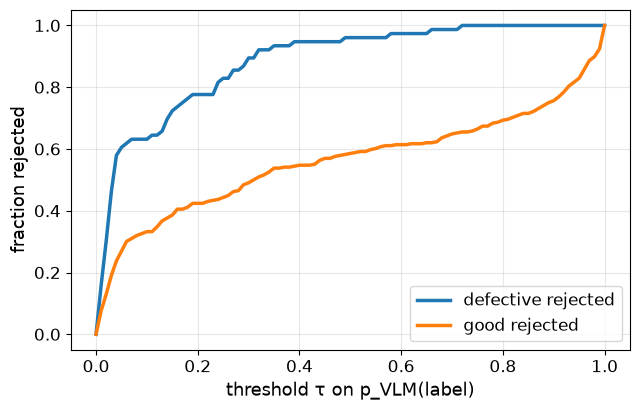

τ = 0.1: отклонено дефектных 0.63, исправных 0.33


In [19]:
from sklearn.metrics import roc_auc_score
K_ = [c for c in CAND if c["fault"] is not None]
bad = np.array([c["fault"] != "none" for c in K_]); pl = np.array([c["vlm_p_label"] for c in K_])
print(f"ROC AUC (1 − p_VLM(label) → дефект): {roc_auc_score(bad, 1 - pl):.3f}")
for f in ["label_bug", "off_frame", "low_contrast", "same_color"]:
    sel = np.array([c["fault"] == f for c in K_])
    if sel.sum():
        print(f"  AUC только для {f:12s} (n={sel.sum():2d}): {roc_auc_score(np.r_[np.zeros((~bad).sum()), np.ones(sel.sum())], 1 - np.r_[pl[~bad], pl[sel]]):.3f}")
taus = np.linspace(0, 1, 101)
fr_good = [(pl[~bad] < t).mean() for t in taus]; rec_bad = [(pl[bad] < t).mean() for t in taus]
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(taus, rec_bad, lw=2.5, label="defective rejected"); ax.plot(taus, fr_good, lw=2.5, label="good rejected")
ax.set_xlabel("threshold τ on p_VLM(label)", fontsize=13); ax.set_ylabel("fraction rejected", fontsize=13)
ax.tick_params(labelsize=12); ax.legend(fontsize=12); ax.grid(alpha=0.3); plt.tight_layout(); plt.savefig(ART / "vlm_threshold.png", dpi=110); plt.show()
TAU = 0.1
print(f"τ = {TAU}: отклонено дефектных {(pl[bad] < TAU).mean():.2f}, исправных {(pl[~bad] < TAU).mean():.2f}")

Проверим смещение проверяющего: отклоняет ли VLM исправные примеры равномерно или чаще отклоняет трудные. Трудными назовём исправные программные примеры с сильным размытием (> 0,8), низким контрастом (< 0,6) или соседними цифрами с обеих сторон.

In [20]:
def hard_flag(spec):
    return bool(spec and (spec.get("blur", 0) > 0.8 or spec.get("contrast", 1) < 0.6 or len(spec.get("neighbors", [])) == 2))
good = [c for c in CAND if c["fault"] == "none" and c["source"] in ("render", "composite")]
gdf = pd.DataFrame([{"hard": hard_flag(c["spec"]), "vlm_reject": c["vlm_p_label"] < TAU, "vlm_correct": c["vlm_pred"] == c["label"]} for c in good])
print(gdf.groupby("hard").agg(n=("vlm_reject", "size"), false_reject=("vlm_reject", "mean"), vlm_acc=("vlm_correct", "mean")).round(3))

         n  false_reject  vlm_acc
hard                             
False   83         0.217    0.639
True   206         0.369    0.476


Что видно. Правила ловят большую часть того, для чего написаны: 93% `off_frame`, 83% `same_color`, 71% `low_contrast`. Но они же отклоняют 11,7% исправных примеров (на трудных, но допустимых сценах контраст по маске бывает ниже порога), а `label_bug` почти не видят: 10% отклонённых среди них — случайные совпадения с другими нарушениями. VLM устроена наоборот: лучше всего она находит именно `label_bug` (AUC 0,80), но сама слаба на маленьких зашумлённых изображениях — на 96 реальных цифрах SVHN её точность 0,49, ниже, чем у нашей CNN на синтетике (0,626). При $\tau = 0{,}1$ она отклоняет 63% дефектных и 33% исправных примеров.

Отклоняет она исправные неравномерно: среди трудных исправных отброшено 36,9%, среди лёгких — 21,7%; точность VLM на них 0,48 и 0,64. Фильтр по слабому проверяющему сдвигает датасет к лёгким примерам, то есть убирает именно то разнообразие, ради которого делалась domain randomization.

Отсюда три правила:

1. Сначала измерьте проверяющего на реальных данных вашего домена. Здесь его accuracy на SVHN ниже, чем у нашей CNN, обученной на синтетике; такой VLM годится как сигнал для ранжирования и аудита, но не как окончательный судья.
2. Комбинируйте проверки с разными слепыми зонами: правила по привилегированной информации генератора + независимая модель.
3. Измеряйте, что фильтр выбрасывает, а не только что он оставляет: распределение отклонённых по трудности и по классам.

## 18. Фильтрация и ручной аудит

### 18.1. Комбинированный фильтр

Пример принимается, если прошёл правила (где они применимы) и $p_{\text{VLM}}(\text{label}) \ge \tau$. Для генеративных изображений правил нет, остаётся только VLM.

In [21]:
for c in CAND:
    c["accepted"] = (c["rule_ok"] is not False) and c["vlm_p_label"] >= TAU
    c["rec"].update(checks={"rule_ok": c["rule_ok"], "rule_reasons": c["reasons"], "vlm": VLM_ID, "vlm_revision": VLM_REV,
                            "vlm_pred": c["vlm_pred"], "vlm_p_label": round(c["vlm_p_label"], 4), "tau": TAU},
                    decision="accept" if c["accepted"] else "reject")
fdf = pd.DataFrame([{"source": c["source"], "bad": None if c["fault"] is None else c["fault"] != "none", "accepted": c["accepted"]} for c in CAND])
print(fdf.groupby("source").agg(n=("accepted", "size"), accepted=("accepted", "mean")).round(3))
k = fdf[fdf.bad.notna()]
print(f"\nдоля дефектных: до фильтра {k.bad.mean():.3f}, среди принятых {k[k.accepted].bad.mean():.3f}, "
      f"среди отклонённых {k[~k.accepted].bad.mean():.3f}; потеряно исправных: {(~k[~k.bad.astype(bool)].accepted).mean():.3f}")
print("генеративные: VLM прочитала метку из промпта у", sum(c["vlm_pred"] == c["label"] for c in CAND if c["source"] == "sd-turbo"), "из", len(GEN))

             n  accepted
source                  
composite  129     0.372
llm         45     0.333
render     218     0.670
sd-turbo     8     0.375

доля дефектных: до фильтра 0.194, среди принятых 0.067, среди отклонённых 0.339; потеряно исправных: 0.383
генеративные: VLM прочитала метку из промпта у 0 из 8


### 18.2. Аудит: оценка остаточной ошибки с интервалом

После фильтра остаётся вопрос: сколько дефектов среди принятых? Ответить на него может только независимая проверка — человек на случайной выборке. Выборку стратифицируем по источнику, чтобы редкие источники (LLM, генеративный) не потерялись, и оцениваем долю ошибок с интервалом Уилсона:

$$ \frac{\hat p + \frac{z^2}{2n}}{1 + \frac{z^2}{n}} \;\pm\; \frac{z}{1 + \frac{z^2}{n}} \sqrt{\frac{\hat p(1-\hat p)}{n} + \frac{z^2}{4n^2}}, \qquad z = 1{,}96. $$

В отличие от нормального приближения $\hat p \pm z\sqrt{\hat p(1-\hat p)/n}$, интервал Уилсона не вырождается в точку при $\hat p = 0$: ноль ошибок в 30 проверенных примерах не означает, что ошибок нет.

Роль человека здесь играет известная по построению информация о дефектах (у генеративных изображений её нет, они идут в отдельный ручной просмотр ниже). Это симуляция аудита, а не реальная ручная проверка. Аудируем также выборку из отклонённых: она показывает, сколько исправных данных выбрасывает фильтр.

In [22]:
def wilson(k, n, z=1.96):
    if n == 0:
        return (float("nan"),) * 3
    p = k / n; d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d; h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return p, max(0, c - h), min(1, c + h)

def audit(items, n, seed=0):
    g = np.random.default_rng(seed); by = defaultdict(list)
    for c in items:
        by[c["source"]].append(c)
    total = len(items); picked = []
    for src, lst in by.items():
        k = max(3, round(n * len(lst) / total)); picked += [lst[i] for i in g.permutation(len(lst))[:k]]
    return picked

acc_items = [c for c in CAND if c["accepted"] and c["fault"] is not None]
rej_items = [c for c in CAND if not c["accepted"] and c["fault"] is not None]
for name, items, n in [("принятые", acc_items, 60), ("отклонённые", rej_items, 30)]:
    smp = audit(items, n)
    k_bad = sum(c["fault"] != "none" for c in smp)
    p, lo, hi = wilson(k_bad, len(smp))
    true = np.mean([c["fault"] != "none" for c in items])
    print(f"{name:11s}: аудит {len(smp)} из {len(items)}, дефектных {k_bad} → {p:.3f} [{lo:.3f}, {hi:.3f}]; истинная доля {true:.3f}")
    for c in smp:
        c["rec"]["audit"] = {"audited": True, "defect": c["fault"] != "none", "auditor": "simulated (known injected fault)"}
for h in [0.10, 0.05, 0.02]:
    print(f"чтобы оценить долю ошибок около 5% с точностью ±{h:.0%}, нужно около {math.ceil(1.96 ** 2 * 0.05 * 0.95 / h ** 2)} примеров")

принятые   : аудит 60 из 209, дефектных 5 → 0.083 [0.036, 0.181]; истинная доля 0.067
отклонённые: аудит 30 из 183, дефектных 12 → 0.400 [0.246, 0.577]; истинная доля 0.339
чтобы оценить долю ошибок около 5% с точностью ±10%, нужно около 19 примеров
чтобы оценить долю ошибок около 5% с точностью ±5%, нужно около 73 примеров
чтобы оценить долю ошибок около 5% с точностью ±2%, нужно около 457 примеров


Что видно. Комбинированный фильтр снизил долю дефектных примеров с 19,4% до 6,7% среди принятых, но ценой 38,3% исправных: по источникам принято 67% рендеров, 37% compositing и 33% LLM-спецификаций (у последних много ночных сцен с почти невидимой цифрой, см. раздел 15). Симулированный аудит 60 из 209 принятых нашёл 5 дефектов: оценка 0,083 с 95%-интервалом Уилсона [0,036; 0,181], а истинная доля 0,067 внутри интервала. Ширина интервала показывает, что 60 проверенных примеров дают только порядок величины; для границы ±2 пункта нужно несколько сотен. Аудит отклонённых (12 дефектов из 30, 0,400 [0,246; 0,577]) говорит обратное: больше половины отброшенного было исправным.

Генеративные изображения: метки и решения VLM. Это материал для настоящего ручного аудита: посмотрите на каждую картинку и сравните со столбцом `vlm_pred`.

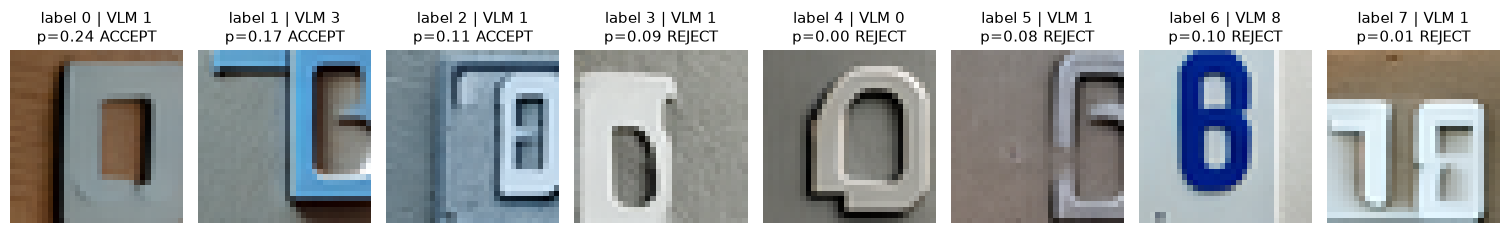

In [23]:
gens = [c for c in CAND if c["source"] == "sd-turbo"]
if gens:
    fig, axes = plt.subplots(1, len(gens[:8]), figsize=(1.9 * len(gens[:8]), 2.4), squeeze=False)
    for ax, c in zip(axes[0], gens[:8]):
        ax.imshow(c["img"]); ax.axis("off")
        ax.set_title(f"label {c['label']} | VLM {c['vlm_pred']}\np={c['vlm_p_label']:.2f} {'ACCEPT' if c['accepted'] else 'REJECT'}", fontsize=11)
    plt.tight_layout(); plt.show()
del vlm; gc.collect()
if HAS_GPU:
    torch.cuda.empty_cache()

Что видно. VLM не предсказала цифру из промпта ни на одном из 8 изображений (чаще всего она отвечает «1»), но 3 из 8 прошли порог $\tau = 0{,}1$, потому что вероятность метки оказалась чуть выше порога: 0,24, 0,17 и 0,11. Из принятых только знак для «0» отдалённо похож на нужную цифру; на двух других нарисовано «7B» и «B» вместо «1» и «2». Значит, для генеративной синтетики слабый проверяющий с низким порогом пропускает ошибки, а высокий порог отбросил бы почти всё; такие изображения нельзя брать в обучение без ручной разметки или сильного проверяющего. На GPU с 64 изображениями при 512×512 доля читаемых цифр может быть другой: этот путь не запускался.

## 19. Дедупликация и проверка утечек

### 19.1. Откуда в синтетике дубликаты

В программной синтетике дубликаты появляются не «из интернета», а из ошибок конвейера:

- повторный запуск с тем же seed (два воркера с одинаковой конфигурацией, перезапуск после сбоя без учёта уже сделанного) — точные копии;
- одна и та же спецификация с другим seed — почти копии: та же цифра, шрифт, цвета и поза, другой шум;
- перекодирование (JPEG, изменение размера) — те же изображения с другими байтами;
- LLM, повторяющая одни и те же спецификации (раздел 15.3), — семантические повторы.

Соберём корпус из 3000 исходных примеров и внесём все три вида копий с известным происхождением. Затем сравним четыре метода: по `spec_id` до рендеринга, по SHA-256 пикселей, по перцептивному хэшу dHash (расстояние Хэмминга) и по косинусной близости эмбеддингов (признаки CNN, обученной на реальных данных, как в SemDeDup).

In [24]:
N_BASE = 3000
Xb, yb, specs_b, recs_b = make_synth("full", N_BASE, seed=31, with_records=True)
corpus = [{"img": x, "rec": r, "origin": i, "kind": "base"} for i, (x, r) in enumerate(zip(Xb, recs_b))]
Xr, _, _, recs_r = make_synth("full", 500, seed=31, with_records=True)                   # перезапуск с тем же seed
corpus += [{"img": x, "rec": r, "origin": i, "kind": "rerun"} for i, (x, r) in enumerate(zip(Xr, recs_r))]
g = np.random.default_rng(5)
for i in g.permutation(N_BASE)[:300]:                                                      # та же спецификация, другой seed
    s2 = {**specs_b[i], "seed": int(specs_b[i]["seed"] + 999_999)}
    im = render(s2); corpus.append({"img": np.array(im), "rec": provenance("render", im, s2), "origin": int(i), "kind": "reseed"})
for i in g.permutation(N_BASE)[:300]:                                                      # перекодирование JPEG
    buf = io.BytesIO(); Image.fromarray(Xb[i]).save(buf, "JPEG", quality=75)
    im = Image.open(io.BytesIO(buf.getvalue())).convert("RGB")
    corpus.append({"img": np.array(im), "rec": provenance("render", im, specs_b[i], reencoded="jpeg75"), "origin": int(i), "kind": "jpeg"})
print(Counter(c["kind"] for c in corpus))

Counter({'base': 3000, 'rerun': 500, 'reseed': 300, 'jpeg': 300})


In [25]:
@torch.no_grad()
def embed(model, X, bs=1024):
    return torch.cat([F.normalize(model.features(to_tensor(X[i:i + bs]).to(DEVICE)), dim=1).cpu() for i in range(0, len(X), bs)])

POPCOUNT = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
def hamming_matrix(h1, h2):
    """Попарные расстояния Хэмминга между 64-битными хэшами (по байтам через таблицу popcount)."""
    a = np.array(h1, dtype=np.uint64)[:, None]; b = np.array(h2, dtype=np.uint64)[None, :]
    x = np.bitwise_xor(a, b)
    return POPCOUNT[x.view(np.uint8).reshape(*x.shape, 8)].sum(-1, dtype=np.uint8)

n = len(corpus); idx_copies = [k for k, c in enumerate(corpus) if c["kind"] != "base"]
H = [int(c["rec"]["dhash"], 16) for c in corpus]
E = embed(M_REAL, np.stack([c["img"] for c in corpus]))
ham = hamming_matrix([H[k] for k in idx_copies], H[:N_BASE])                  # копии × исходные
cos = (E[idx_copies] @ E[:N_BASE].T).numpy()
ham_bb = hamming_matrix(H[:N_BASE], H[:N_BASE]); cos_bb = (E[:N_BASE] @ E[:N_BASE].T).numpy()
iu = np.triu_indices(N_BASE, 1)
spec_ids = Counter(c["rec"]["spec_id"] for c in corpus); shas = Counter(c["rec"]["image_sha256"] for c in corpus)
rows = []
for name, hit, fp in [
    ("spec_id (до рендеринга)", lambda k, j: corpus[k]["rec"]["spec_id"] == corpus[j]["rec"]["spec_id"], None),
    ("SHA-256 пикселей", lambda k, j: corpus[k]["rec"]["image_sha256"] == corpus[j]["rec"]["image_sha256"], None),
    ("dHash, Хэмминг ≤ 6", lambda k, j: ham[idx_copies.index(k), j] <= 6, (ham_bb[iu] <= 6).sum()),
    ("эмбеддинг, cos ≥ 0.98", lambda k, j: cos[idx_copies.index(k), j] >= 0.98, (cos_bb[iu] >= 0.98).sum())]:
    r = {"метод": name}
    for kind in ["rerun", "reseed", "jpeg"]:
        ks = [k for k in idx_copies if corpus[k]["kind"] == kind]
        r[kind] = round(np.mean([hit(k, corpus[k]["origin"]) for k in ks]), 3)
    r["ложные пары среди 3000 исходных"] = 0 if fp is None else int(fp)
    rows.append(r)
print(pd.DataFrame(rows).to_string(index=False))
print(f"\nвсего пар среди исходных: {len(iu[0]):,}")

                  метод  rerun  reseed  jpeg  ложные пары среди 3000 исходных
spec_id (до рендеринга)    1.0   0.000 1.000                                0
       SHA-256 пикселей    1.0   0.000 0.010                                0
     dHash, Хэмминг ≤ 6    1.0   0.513 0.970                               54
  эмбеддинг, cos ≥ 0.98    1.0   0.967 0.883                              702

всего пар среди исходных: 4,498,500


Что видно. Методы образуют лестницу: чем «мягче» сравнение, тем больше видов копий оно находит и тем больше ложных совпадений даёт. `spec_id` и SHA-256 безошибочны и находят все повторные запуски, но SHA-256 не видит ни перекодирования (1% JPEG-копий), ни нового seed, а `spec_id` по построению не различает разный seed. dHash с порогом Хэмминга 6 находит 97% JPEG-копий и половину копий с другим seed, давая 54 ложные пары среди 4,5 миллиона пар исходных примеров. Эмбеддинги с порогом 0,98 находят 97% копий с другим seed и 88% JPEG-копий, но дают 702 ложные пары: на маленьких изображениях с похожими цифрами разные примеры оказываются очень близки. Порог для эмбеддингов подбирают на размеченной выборке пар, а найденные пары просматривают, а не удаляют вслепую.

Практический порядок: дедупликация спецификаций до рендеринга (дёшево и экономит вычисления), затем точная по хэшу пикселей, затем перцептивная, затем семантическая с ручной проверкой пограничных пар.

### 19.2. Утечки: синтетика против test и real train против real test

Отдельная задача — убедиться, что в обучении нет примеров, совпадающих с test. Для синтетики это кажется невозможным, но бывает: если фоны для compositing взяты из того же источника, что и test, или генеративная модель запомнила обучающие изображения. Проверим обе пары: синтетику против real test и официальный train SVHN против нашей подвыборки test. Мера — максимальная нормированная корреляция яркости (косинус центрированных векторов 32×32) до ближайшего соседа.

synth full+photo → real test   max corr: медиана 0.707, 99-й перцентиль 0.881, максимум 0.966, доля ≥ 0.97: 0.0000
SVHN train → real test         max corr: медиана 0.799, 99-й перцентиль 0.925, максимум 0.971, доля ≥ 0.97: 0.0002


точных совпадений train/test: 0


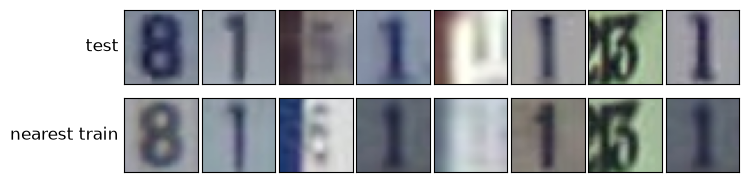

In [26]:
def gray_vec(X):
    x = torch.as_tensor(X).float().mean(-1).reshape(len(X), -1)
    x = x - x.mean(1, keepdim=True)
    return x / (x.norm(dim=1, keepdim=True) + 1e-6)

def nn_max(A, B, bs=1000):
    best, arg = [], []
    for i in range(0, len(B), bs):
        s = B[i:i + bs] @ A.T; v, j = s.max(1); best.append(v); arg.append(j)
    return torch.cat(best).numpy(), torch.cat(arg).numpy()

Vte = gray_vec(Xte)
b_syn, _ = nn_max(gray_vec(SYN["photo"][0]), Vte)
b_tr, a_tr = nn_max(gray_vec(Xtr_all), Vte)
for name, b in [("synth full+photo → real test", b_syn), ("SVHN train → real test", b_tr)]:
    print(f"{name:30s} max corr: медиана {np.median(b):.3f}, 99-й перцентиль {np.percentile(b, 99):.3f}, "
          f"максимум {b.max():.3f}, доля ≥ 0.97: {(b >= 0.97).mean():.4f}")
exact = set(hashlib.sha256(x.tobytes()).hexdigest() for x in Xte)
print("точных совпадений train/test:", sum(hashlib.sha256(x.tobytes()).hexdigest() in exact for x in Xtr_all))
top = np.argsort(-b_tr)[:8]
show_grid([Xte[top], Xtr_all[a_tr[top]]], ["test", "nearest train"], n=8)

Что видно. Синтетика не содержит почти-копий test: максимальная корреляция 0,966, ни одной пары выше порога 0,97. Между официальным train SVHN и нашей подвыборкой test точных совпадений нет, но одна пара из 5000 (0,02%) прошла порог (0,971), и несколько ближайших пар на рисунке выглядят как одна и та же табличка, снятая с другого кадра или с небольшим сдвигом (например, «8» и «13»). Это не утечка в строгом смысле, но такие пары завышают точность на test, и при серьёзной оценке их стоит разметить и исключить. Для сравнения: в CIFAR такая проверка нашла почти-дубликаты для 3,3% изображений test CIFAR-10 и 10% test CIFAR-100 ([Barz, Denzler, 2020](https://arxiv.org/abs/1902.00423)). Проверку стоит повторять при каждом новом источнике фонов, текстур или генеративной модели.

## 20. Отбор сложных примеров

Синтетику можно генерировать без ограничений, а обучение — нет. Если бюджет обучения фиксирован, естественная идея — оставить «полезные» примеры. Проверим четыре стратегии отбора $N_{\text{sel}}$ примеров из большого пула:

- `random` — случайные;
- `easy` — с наименьшим loss оценочной модели;
- `hardest` — с наибольшим loss (как в OHEM);
- `hard, filtered` — сначала убрать примеры, где оценочная модель уверенно (вероятность ≥ 0,9) не согласна с меткой, затем взять самые трудные из оставшихся.

Чтобы эксперимент был честным по отношению к реальным конвейерам, в пул внесём 8% неверных меток (тип `label_bug` из раздела 17). Оценочная модель — `M_PHOTO`, обученная на другом наборе синтетики. Важно, сколько неверных меток попадает в каждую выборку.

In [27]:
t0 = time.time()
Xp, yp_true, _ = make_synth("full", S["n_pool"], seed=41, textures=TEXTURES)
g = np.random.default_rng(8)
noisy = g.random(len(yp_true)) < 0.08
yp = yp_true.copy(); yp[noisy] = (yp_true[noisy] + g.integers(1, 10, noisy.sum())) % 10
P = predict(M_PHOTO, Xp)
loss = -np.log(P[np.arange(len(yp)), yp] + 1e-9)
confident_disagree = (P.max(1) >= 0.9) & (P.argmax(1) != yp)
N_SEL = S["n_syn"] // 2
order = np.argsort(loss)
keep = np.where(~confident_disagree)[0]
SELECT = {"random": g.permutation(len(yp))[:N_SEL], "easy": order[:N_SEL], "hardest": order[-N_SEL:],
          "hard, filtered": keep[np.argsort(loss[keep])][-N_SEL:]}
print(f"пул {len(yp)}, неверных меток {noisy.mean():.3f}; уверенных несогласий {confident_disagree.mean():.3f}, "
      f"из них неверные метки: {noisy[confident_disagree].mean():.3f} | {time.time() - t0:.0f} с")
for name, idx in SELECT.items():
    m = train_cnn([(Xp[idx], yp[idx], 1.0)], steps_for(N_SEL))
    r = evaluate(f"select: {name}", m, note=f"noise {noisy[idx].mean():.3f}")
    print(f"{'':28s} доля неверных меток в выборке: {noisy[idx].mean():.3f}")

пул 40000, неверных меток 0.081; уверенных несогласий 0.038, из них неверные метки: 0.973 | 70 с


select: random               real test 0.485 [0.472, 0.499]  real val 0.382
                             доля неверных меток в выборке: 0.085


select: easy                 real test 0.486 [0.472, 0.499]  real val 0.389
                             доля неверных меток в выборке: 0.000


select: hardest              real test 0.181 [0.170, 0.192]  real val 0.152
                             доля неверных меток в выборке: 0.320


select: hard, filtered       real test 0.240 [0.228, 0.252]  real val 0.195
                             доля неверных меток в выборке: 0.174


Что видно. Отбор «самых трудных» по loss собирает в выборку в первую очередь неверные метки: среди 10 тысяч самых трудных их 32% при 8% в пуле, и точность на real test падает с 0,485 (случайный отбор) до 0,181. Для модели пример с неправильной меткой и есть самый трудный. Удаление уверенных несогласий (3,8% пула, из них 97% действительно неверные метки) снижает шум в трудной выборке до 17,4% и поднимает точность до 0,240, но это всё ещё вдвое хуже случайного отбора. Очистка помогла, но не превратила «трудные» в полезные: оценочная модель уверенно ловит только половину неверных меток, а среди оставшихся трудных, вероятно, много почти нерешаемых (сильное размытие, низкий контраст); это предположение мы не проверяли.

Отбор лёгких примеров убрал шум полностью (0% неверных меток), но дал ту же точность, что случайный отбор: 0,486 против 0,485. Лёгкие примеры чище, но несут меньше новой информации, и в нашем прогоне эти эффекты уравновесились. Это согласуется с выводом Sorscher et al. из раздела 6.3: при небольшом объёме данных трудные примеры не выгодны, а какая стратегия лучше, проверяют на реальной валидации, а не выбирают по умолчанию.

## 21. Domain gap: доменный классификатор и расстояние Фреше

Измерим разрыв между каждым вариантом синтетики и реальными данными двумя способами из раздела 7.

1. Proxy A-distance: учим ту же CNN отличать синтетические изображения от реальных (2000 + 2000), измеряем ошибку $\varepsilon$ на отложенных 1000 + 1000 и считаем $\hat d_A = 2(1 - 2\varepsilon)$. Значение 0 означает «неразличимы», 2 — «различимы идеально».
2. Расстояние Фреше (FD) между гауссовыми приближениями признаков:

$$ \mathrm{FD} = \lVert \mu_s - \mu_r \rVert^2 + \operatorname{tr}\!\left(\Sigma_s + \Sigma_r - 2(\Sigma_s \Sigma_r)^{1/2}\right). $$

Признаки берём из `M_REAL` — модели, обученной на реальных цифрах (аналог Inception в FID, но для нашего домена). Реальные изображения для этих измерений — отдельная часть real train pool, не test. Для контроля в таблицу добавлена строка «real vs real»: два непересекающихся набора реальных цифр.

In [28]:
from scipy import linalg
N_REF = len(REF_IDX)
GAP_IDX = POOL_IDX[N_REF:N_REF + 6000]
Xg = Xtr_all[GAP_IDX]

def frechet(f1, f2):
    mu1, mu2 = f1.mean(0), f2.mean(0); s1, s2 = np.cov(f1, rowvar=False), np.cov(f2, rowvar=False)
    covmean = linalg.sqrtm(s1 @ s2).real
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1 + s2 - 2 * covmean))

@torch.no_grad()
def feats(model, X, bs=1024):
    return torch.cat([model.features(to_tensor(X[i:i + bs]).to(DEVICE)).cpu() for i in range(0, len(X), bs)]).numpy()

def proxy_a_distance(Xs, Xr, seed=0):
    n = min(len(Xs), len(Xr), 3000); k = 2 * n // 3          # 2/3 — обучение доменного классификатора, 1/3 — отложенная оценка
    Xtr_ = np.concatenate([Xs[:k], Xr[:k]]); ytr_ = np.r_[np.ones(k), np.zeros(k)].astype(np.int64)
    Xho = np.concatenate([Xs[k:n], Xr[k:n]]); yho = np.r_[np.ones(n - k), np.zeros(n - k)]
    m = train_cnn([(Xtr_, ytr_, 1.0)], steps_for(2 * k, 4), seed=seed)
    err = (predict(m, Xho).argmax(1) != yho).mean()
    return 2 * (1 - 2 * err)

f_real = feats(M_REAL, Xg[3000:6000])
GAP = []
variants = [("clean", SYN["clean"][0]), ("light", SYN["light"][0]), ("full", SYN["full"][0]), ("full + photo", SYN["photo"][0]),
            ("real vs real", Xg[:3000])]
name_map = {"clean": "synth clean", "light": "synth light", "full": "synth full", "full + photo": "synth full + photo"}
for name, X in variants:
    t0 = time.time()
    da = proxy_a_distance(X[:3000], Xg[3000:6000] if name != "real vs real" else Xtr_all[POOL_IDX[N_REF + 6000:N_REF + 9000]])
    fd = frechet(feats(M_REAL, X[:3000]), f_real)
    acc = next((v["real_test"] for k, v in RESULTS.items() if name in name_map and k.startswith(name_map[name] + " (")), None)
    GAP.append({"variant": name, "proxy A-distance": round(da, 3), "FD (M_REAL features)": round(fd, 2),
                "real test acc": None if acc is None else round(acc, 3)})
print(pd.DataFrame(GAP).to_string(index=False))

     variant  proxy A-distance  FD (M_REAL features)  real test acc
       clean             2.000                 20.88          0.068
       light             2.000                 11.81          0.151
        full             1.802                  3.42          0.626
full + photo             1.796                  3.55          0.615
real vs real            -0.010                  0.04            NaN


Что видно. FD упорядочивает варианты так же, как точность на real test: `clean` 20,9 → `light` 11,8 → `full` 3,4 и `full + photo` 3,6, и обратный порядок точности 0,068 → 0,151 → 0,626 и 0,615. Даже маленькая разница между `full` и `full + photo` совпала по знаку, хотя она меньше ширины интервалов точности. Proxy A-distance насыщается: у `clean` и `light` она равна 2,0 (доменный классификатор не ошибся ни разу), у `full` и `full + photo` — 1,80, то есть даже лучшую синтетику классификатор отличает от реальных цифр примерно в 95% случаев. При этом модель на этой синтетике даёт 0,626 на реальных данных. «Неотличимость» — гораздо более сильное требование, чем «полезность»: синтетика может быть легко отличима по деталям, не важным для задачи (характер шума, резкость краёв, отсутствие оптических артефактов).

Поэтому меры разрыва — инструмент диагностики и ранжирования вариантов генератора, а не замена оценки на реальном test. Строка «real vs real» показывает нижнюю границу мер на конечной выборке.

## 22. Смеси real/synthetic

Главный практический вопрос: сколько реальных данных нужно, если есть синтетика, и как их объединять. Сравниваем четыре стратегии при $N_{\text{real}} \in \{250, 1000, 4000\}$ (на GPU добавляется 16 000):

- `real only` — только реальные данные (больше эпох для маленьких выборок, чтобы не было недообучения);
- `synth only` — модель `M_PHOTO` из раздела 14, реальных данных ноль;
- `mix` — совместное обучение, в каждом батче доля реальных примеров $r = 0{,}3$ (реальные примеры повторяются чаще синтетических);
- `pretrain → finetune` — `M_PHOTO` дообучается на реальных данных с меньшим learning rate.

Реальные подвыборки вложены друг в друга (250 ⊂ 1000 ⊂ 4000), чтобы различия между $N$ не смешивались с различиями выборок. Пропорцию $r$ для `mix` при $N = 1000$ выбираем по real val из $\{0{,}1;\ 0{,}3;\ 0{,}6\}$ — так выглядит правильная процедура выбора гиперпараметра: решение по реальной валидации, итоговое число — по test.

In [29]:
N_LIST = [250, 1000, 4000] + ([] if FAST_DEV_RUN else [16000])
MIX_IDX = POOL_IDX[-16000:]
Xs_mix, ys_mix = SYN["photo"][0], SYN["photo"][1]
MIX = []
for n in N_LIST:
    Xr_, yr_ = Xtr_all[MIX_IDX[:n]], ytr_all[MIX_IDX[:n]]
    t0 = time.time()
    m = train_cnn([(Xr_, yr_, 1.0)], max(steps_for(n, 30 if n <= 1000 else 15), 300))
    MIX.append({"N_real": n, "strategy": "real only", **evaluate(f"real only, N={n}", m)})
    m = train_cnn([(Xs_mix, ys_mix, 0.7), (Xr_, yr_, 0.3)], steps_for(len(ys_mix)))
    MIX.append({"N_real": n, "strategy": "mix r=0.3", **evaluate(f"mix r=0.3, N={n}", m)})
    m = train_cnn([(Xr_, yr_, 1.0)], max(steps_for(n, 10), 200), lr=1e-3, init=M_PHOTO.state_dict())
    MIX.append({"N_real": n, "strategy": "pretrain → finetune", **evaluate(f"pretrain → finetune, N={n}", m)})
    print(f"  N={n}: {time.time() - t0:.0f} с")

real only, N=250             real test 0.319 [0.306, 0.332]  real val 0.342


mix r=0.3, N=250             real test 0.710 [0.697, 0.722]  real val 0.646


pretrain → finetune, N=250   real test 0.654 [0.641, 0.667]  real val 0.652
  N=250: 91 с


real only, N=1000            real test 0.521 [0.507, 0.536]  real val 0.513


mix r=0.3, N=1000            real test 0.772 [0.760, 0.783]  real val 0.731


pretrain → finetune, N=1000  real test 0.750 [0.738, 0.762]  real val 0.751
  N=1000: 94 с


real only, N=4000            real test 0.694 [0.681, 0.707]  real val 0.680


mix r=0.3, N=4000            real test 0.801 [0.790, 0.812]  real val 0.764


pretrain → finetune, N=4000  real test 0.805 [0.794, 0.816]  real val 0.791
  N=4000: 110 с


In [30]:
n = 1000; Xr_, yr_ = Xtr_all[MIX_IDX[:n]], ytr_all[MIX_IDX[:n]]
ratio_rows = [{"r": 0.3, **RESULTS[f"mix r=0.3, N={n}"]}]
for r in [0.1, 0.6]:
    m = train_cnn([(Xs_mix, ys_mix, 1 - r), (Xr_, yr_, r)], steps_for(len(ys_mix)))
    ratio_rows.append({"r": r, **evaluate(f"mix r={r}, N={n}", m)})
rdf = pd.DataFrame(ratio_rows).sort_values("r")
best_r = rdf.loc[rdf.real_val.idxmax(), "r"]
print(rdf[["r", "real_val", "real_test", "ci_lo", "ci_hi"]].round(3).to_string(index=False))
print(f"по real val выбрано r = {best_r}; его real test = {rdf.loc[rdf.r == best_r, 'real_test'].item():.3f}")

mix r=0.1, N=1000            real test 0.752 [0.740, 0.764]  real val 0.692


mix r=0.6, N=1000            real test 0.750 [0.738, 0.762]  real val 0.687
  r  real_val  real_test  ci_lo  ci_hi
0.1     0.692      0.752  0.740  0.764
0.3     0.731      0.772  0.760  0.783
0.6     0.687      0.750  0.738  0.762
по real val выбрано r = 0.3; его real test = 0.772


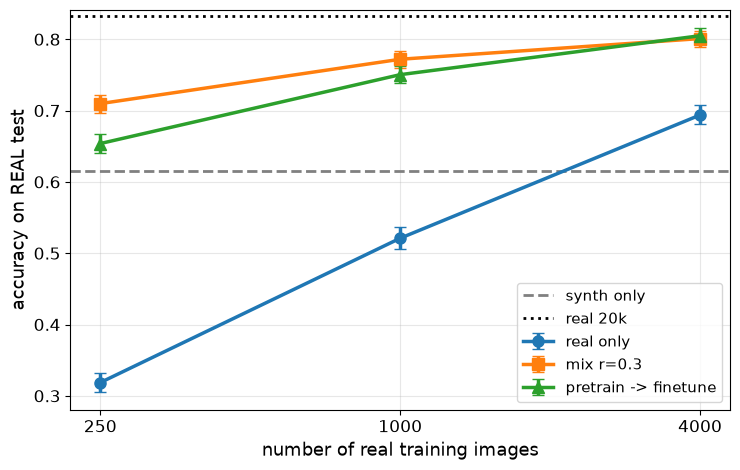

strategy  mix r=0.3  pretrain → finetune  real only
N_real                                             
250           0.710                0.654      0.319
1000          0.772                0.750      0.521
4000          0.801                0.805      0.694


In [31]:
mdf = pd.DataFrame(MIX)
fig, ax = plt.subplots(figsize=(7.5, 4.8))
for strat, mk in [("real only", "o"), ("mix r=0.3", "s"), ("pretrain → finetune", "^")]:
    d = mdf[mdf.strategy == strat]
    ax.errorbar(d.N_real, d.real_test, yerr=[d.real_test - d.ci_lo, d.ci_hi - d.real_test], marker=mk, ms=8, lw=2.5, capsize=4,
                label=strat.replace("→", "->"))
syn_only = RESULTS[f"synth full + photo ({S['n_syn'] // 1000}k)"]["real_test"]
ceil = [v for k, v in RESULTS.items() if k.startswith("real (")][0]["real_test"]
ax.axhline(syn_only, ls="--", c="gray", lw=2, label="synth only")
ax.axhline(ceil, ls=":", c="k", lw=2, label=f"real {len(REF_IDX) // 1000}k")
ax.set_xscale("log"); ax.minorticks_off(); ax.set_xticks(N_LIST); ax.set_xticklabels(N_LIST)
ax.set_xlabel("number of real training images", fontsize=13); ax.set_ylabel("accuracy on REAL test", fontsize=13)
ax.tick_params(labelsize=12); ax.grid(alpha=0.3); ax.legend(fontsize=11, loc="lower right")
plt.tight_layout(); plt.savefig(ART / "mixtures.png", dpi=110); plt.show()
print(mdf.pivot(index="N_real", columns="strategy", values="real_test").round(3))

Что видно. При малом числе реальных изображений синтетика даёт большой выигрыш. При $N_{\text{real}} = 250$ одни реальные данные дают 0,319, а `mix` — 0,710 и `pretrain → finetune` — 0,654; обе стратегии лучше и модели только на синтетике (0,615). При $N = 1000$: 0,521 против 0,772 и 0,750. При $N = 4000$: 0,694 против 0,801 и 0,805. `mix` с 1000 реальных изображений (0,772) лучше, чем 4000 реальных изображений без синтетики (0,694), то есть в этом диапазоне синтетика заменяет больше чем в четыре раза больше реальных данных. С ростом $N_{\text{real}}$ выигрыш уменьшается (с 39 до 11 пунктов), но в нашем диапазоне не исчезает; до потолка на 20 тысячах реальных (0,833) лучшая смесь не дотягивает 3 пункта. Это та же картина, что в Playing for Data и Cut, Paste and Learn (раздел 8): синтетика не заменяет реальные данные, а снижает их необходимое количество.

`mix` лучше при малом $N$ (0,710 против 0,654 при 250), при $N = 4000$ стратегии сравнялись (0,801 и 0,805, интервалы перекрываются). Fine-tuning дешевле: синтетическую модель обучают один раз, а затем быстро дообучают на любой реальной выборке. Доля $r = 0{,}3$, выбранная по real val (0,731 против 0,692 и 0,687), оказалась лучшей и на real test, но так бывает не всегда: решение принимается по валидации, а test только фиксирует результат.

## 23. Provenance-манифест, воспроизводимость и карточка датасета

### 23.1. Манифест

Соберём записи всех кандидатов из разделов 15–18 в `manifest.jsonl`: одна строка на пример. Для каждого — источник, метка, спецификация или промпт с параметрами генерации, версии кода и моделей, хэши, результаты проверок, решение фильтра и отметка аудита. Изображения сохраняются отдельно, имя файла — `id` записи.

In [32]:
MAN = ART / "manifest"; (MAN / "images").mkdir(parents=True, exist_ok=True)
with open(MAN / "manifest.jsonl", "w") as f:
    for c in CAND:
        Image.fromarray(c["img"]).save(MAN / "images" / f"{c['rec']['id']}.png")
        f.write(json.dumps({**c["rec"], "file": f"images/{c['rec']['id']}.png"}, ensure_ascii=False, default=str) + "\n")
with open(MAN / "llm_attempts.jsonl", "w") as f:
    for r in LLM_RECS:
        f.write(json.dumps({"context": r["context"], "attempts": r["attempts"], "valid": r["spec"] is not None, "llm": LLM_ID,
                            "llm_revision": LLM_REV, "generation": GEN_KW}, ensure_ascii=False) + "\n")
lines = (MAN / "manifest.jsonl").read_text().splitlines()
print(f"manifest.jsonl: {len(lines)} записей, {(MAN / 'manifest.jsonl').stat().st_size / 1024:.0f} КБ")
print(json.dumps(json.loads(lines[0]), ensure_ascii=False, indent=1)[:1500])

manifest.jsonl: 400 записей, 428 КБ
{
 "source": "render",
 "label": 3,
 "image_sha256": "3435fd586525bf3dbf610ba6a61d390ee86e366020c17ee62e565df815ac8c23",
 "dhash": "c7cbdbd1dbfbf3e6",
 "spec": {
  "digit": 3,
  "seed": 70000000,
  "level": "full",
  "font": "DejaVuSansMono-BoldOblique.ttf",
  "fg_rgb": [
   75,
   228,
   152
  ],
  "bg": "photo",
  "bg_rgb": [
   98,
   105,
   115
  ],
  "bg_rgb2": [
   185,
   153,
   74
  ],
  "bg_tex": 780,
  "scale": 1.0427669744606995,
  "rotation": 3.746096441865692,
  "shear": -0.02984904814922784,
  "dx": -0.059968259522345774,
  "dy": -0.028769295554602333,
  "neighbors": [
   {
    "digit": 7,
    "dx": 0.5907719597025067
   }
  ],
  "blur": 0.5361177473561718,
  "noise": 7.276636087981135,
  "contrast": 0.7011365204923832,
  "jpeg": 0,
  "shadow": 0
 },
 "spec_id": "82fcf2c8a076f17a",
 "renderer": "8b994153f0be",
 "font_sha": "a69081c15c76",
 "fault_injected": "none",
 "id": "render-3435fd586525",
 "checks": {
  "rule_ok": true,
  "rule

### 23.2. Проверка воспроизводимости по манифесту

Манифест полезен, только если по нему действительно можно получить те же данные. Перерендерим случайные 50 программных записей из манифеста (без дефектов: у них спецификация совпадает с нарисованным) и сравним SHA-256 пикселей с сохранёнными.

In [33]:
recs = [json.loads(l) for l in lines]
prog = [r for r in recs if r["source"] in ("render", "llm+render") and r.get("fault_injected", "none") == "none"]
g = np.random.default_rng(0)
sample = [prog[i] for i in g.permutation(len(prog))[:50]]
same = sum(hashlib.sha256(np.array(render(r["spec"], TEXTURES)).tobytes()).hexdigest() == r["image_sha256"] for r in sample)
print(f"совпало побайтно: {same} из {len(sample)}; версия рендерера в записях: {set(r['renderer'] for r in sample)}, текущая: {RENDERER_VERSION}")

совпало побайтно: 50 из 50; версия рендерера в записях: {'8b994153f0be'}, текущая: 8b994153f0be


Для генеративных записей побайтного совпадения ждать нельзя: результат диффузионной модели при том же seed может отличаться на другом GPU, другой версии библиотек или в другой точности. Поэтому для них в манифесте хранится и сам файл, и все параметры: воспроизводимость на уровне «могу сгенерировать похожее и объяснить, откуда взялось это», а не на уровне битов.

### 23.3. Карточка датасета

Карточка собирается автоматически из манифеста и результатов: состав по источникам, доли принятых, оценка остаточной ошибки, известные ограничения, лицензии источников и то, на чём проверялась полезность. Последнее — самое важное поле карточки синтетического датасета: «проверено на real test SVHN, точность такая-то», а не «выглядит реалистично».

In [34]:
src_tab = pd.DataFrame([{"source": r["source"], "decision": r["decision"]} for r in recs]).value_counts().unstack(fill_value=0)
card = f"""# Synthetic house-number digits (lecture 10 demo)

## Composition
```
{src_tab.to_string()}
```

## Generation
- renderer: code sha256 `{RENDERER_VERSION}`, {len(FONTS)} fonts from matplotlib, domain randomization level `full`
- compositing backgrounds: 16x16 crops of CIFAR-10 test images
- LLM specs: `{LLM_ID}` rev `{LLM_REV[:12]}`, T={GEN_KW['temperature']}, top_p={GEN_KW['top_p']}; class balance enforced by quota, not by the LLM
- generative: `{GEN_ID}` rev `{GEN_REV[:12]}`, 1 step, guidance 0, {S['gen_res']}px, center crop 50%

## Quality control
- rule checks (mask-based): target in frame, visible contrast
- VLM check: `{VLM_ID}`, reject if p(label) < {TAU}
- audit: stratified sample, simulated auditor (known injected faults) — not a human audit

## Utility (evaluated on REAL data only)
- real test: SVHN test, {len(yte)} images{' (random subset)' if FAST_DEV_RUN else ''}
- synth only (full + photo): {syn_only:.3f}; real {len(REF_IDX) // 1000}k: {ceil:.3f}

## Known limitations
- small VLM verifier is weak on 32x32 images and biased against hard examples
- generated images: label from prompt is often wrong; keep only after VLM check and human review
- no near-duplicates of real test found at corr >= 0.97 (pixel space); re-run for new background sources

## Licenses of sources (check before use)
- SVHN: http://ufldl.stanford.edu/housenumbers/
- CIFAR-10: https://www.cs.toronto.edu/~kriz/cifar.html
- SD-Turbo: https://huggingface.co/stabilityai/sd-turbo
- Qwen2.5-0.5B-Instruct: https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct
- SmolVLM-256M-Instruct: https://huggingface.co/HuggingFaceTB/SmolVLM-256M-Instruct
"""
(MAN / "DATASET_CARD.md").write_text(card)
print(card)

# Synthetic house-number digits (lecture 10 demo)

## Composition
```
decision    accept  reject
source                    
render         194     153
llm+render      15      30
sd-turbo         3       5
```

## Generation
- renderer: code sha256 `8b994153f0be`, 21 fonts from matplotlib, domain randomization level `full`
- compositing backgrounds: 16x16 crops of CIFAR-10 test images
- LLM specs: `Qwen/Qwen2.5-0.5B-Instruct` rev `7ae557604adf`, T=0.9, top_p=0.95; class balance enforced by quota, not by the LLM
- generative: `stabilityai/sd-turbo` rev `b261bac6fd2c`, 1 step, guidance 0, 384px, center crop 50%

## Quality control
- rule checks (mask-based): target in frame, visible contrast
- VLM check: `HuggingFaceTB/SmolVLM-256M-Instruct`, reject if p(label) < 0.1
- audit: stratified sample, simulated auditor (known injected faults) — not a human audit

## Utility (evaluated on REAL data only)
- real test: SVHN test, 5000 images (random subset)
- synth only (full + photo): 0.615; real 

### 23.4. Итоговая таблица и конфигурация прогона

In [35]:
TAB = pd.DataFrame(RESULTS).T
print(TAB[["real_test", "ci_lo", "ci_hi", "real_val"] + (["synth_val"] if "synth_val" in TAB else []) + ["note"]].to_string())
RUN_CONFIG = {"fast_dev_run": FAST_DEV_RUN, "device": DEVICE, "seed": SEED, "sizes": S, "versions": VERSIONS,
              "renderer": RENDERER_VERSION, "fonts": FONT_SHA, "llm": [LLM_ID, LLM_REV], "vlm": [VLM_ID, VLM_REV], "generator": [GEN_ID, GEN_REV],
              "tau": TAU, "results": {k: {kk: (float(vv) if isinstance(vv, (float, np.floating)) else vv) for kk, vv in v.items()} for k, v in RESULTS.items()},
              "domain_gap": GAP}
(ART / "run_config.json").write_text(json.dumps(RUN_CONFIG, ensure_ascii=False, indent=1, default=str))
print(f"\nrun_config.json: {(ART / 'run_config.json').stat().st_size / 1024:.1f} КБ")

                            real_test     ci_lo     ci_hi real_val synth_val         note
synth clean (10k)              0.0684     0.061    0.0762    0.085       1.0         37 s
synth light (10k)              0.1512    0.1406    0.1604     0.11       1.0         40 s
synth full (20k)                0.626  0.612595   0.63921    0.513     0.963         92 s
real (20k), потолок            0.8332  0.822595     0.844    0.834       NaN         57 s
synth full + photo (20k)       0.6148   0.60119    0.6282    0.497     0.877        105 s
select: random                 0.4854    0.4722    0.4992    0.382       NaN  noise 0.085
select: easy                   0.4858    0.4718   0.49901    0.389       NaN  noise 0.000
select: hardest                0.1806    0.1702    0.1916    0.152       NaN  noise 0.320
select: hard, filtered         0.2404  0.227795    0.2522    0.195       NaN  noise 0.174
real only, N=250               0.3186   0.30599  0.332205    0.342       NaN             
mix r=0.3,

# Выводы практикума

Все числа — из сохранённого CPU-прогона (`FAST_DEV_RUN`: 20 тысяч синтетических примеров на обучение, 6 эпох, real test — случайные 5000 изображений SVHN test). На GPU с полными выборками блокнот не запускался, и числа там будут другими.

| Опыт | Real test | Что показывает |
|---|---|---|
| synth clean, 10k | 0,068 | synth val 1,000: узкая синтетика выглядит идеально и не переносится |
| synth light, 10k | 0,151 | synth val снова 1,000 |
| synth full (DR), 20k | 0,626 [0,613; 0,639] | domain randomization даёт основной скачок |
| synth full + photo, 20k | 0,615 [0,601; 0,628] | реальные фоны CIFAR-10 эффекта не дали |
| real only, 1000 | 0,521 | — |
| mix r = 0,3: 20k synth + 1000 real | 0,772 | лучше, чем 4000 реальных без синтетики (0,694) |
| real, 20k (потолок) | 0,833 [0,823; 0,844] | до потолка лучшей смеси с 4000 real около 3 пунктов |

Главное:

1. Синтетическая валидация выбрала бы худшую модель: её ранжирование обратно ранжированию по real test. Все решения принимались по real val, итог — по real test.
2. LLM-спецификации: как есть валидны 33%, после ремонта формата 83%, после повтора 94%; распределения полей сильно смещены (ночь в 73%, семёрка в 31%). Баланс и покрытие задаёт код.
3. Генеративная синтетика sd-turbo на CPU (1 шаг, 384×384) не дала ни одной однозначно читаемой нужной цифры из 8; метка из промпта без проверки — это шум разметки.
4. Проверки: правила ловят дефекты рендера, VLM — несоответствие метки (AUC 0,80 для `label_bug`), но слабая VLM отбрасывает треть исправных примеров, причём трудные чаще (36,9% против 21,7%). Фильтр снизил долю дефектов с 19,4% до 6,7%; аудит 60 принятых дал 0,083 [0,036; 0,181].
5. Дедупликация — лестница с компромиссом между полнотой и ложными парами; утечек синтетики в test не найдено, между train и test SVHN есть отдельные очень близкие пары.
6. Отбор «самых трудных» без очистки собрал 32% неверных меток и уронил точность до 0,181; очистка помогла лишь частично.
7. FD упорядочила варианты синтетики так же, как точность; proxy A-distance насыщена (1,80–2,00): полезная синтетика может быть легко отличима от реальной.

Что не проверено: GPU-путь с полными размерами; ручной аудит человеком (аудитор симулирован по известным внедрённым дефектам); переносимость выводов на более крупные модели и другие задачи.

# Контрольные вопросы

1. Назовите четыре причины использовать синтетические данные. Для какой из них синтетика от генеративной модели подходит хуже всего и почему?
2. Сравните программный рендеринг, compositing и генеративные модели по трём осям: точность метки, реалистичность, управляемость. Где в каждом источнике возникает domain gap?
3. Почему в работе Tremblay et al. нереалистичная DR-синтетика не уступила фотореалистичному Virtual KITTI? Что меняет structured domain randomization?
4. Какие факторы в domain randomization нужно варьировать, а какие нельзя? Приведите пример, когда рандомизация делает пример нерешаемым.
5. Перечислите шесть шагов конвейера синтетики и для каждого — что записывается в provenance.
6. Зачем LLM в конвейере, если есть равномерный сэмплер? Какие обязанности нельзя доверять LLM и почему?
7. Чем отличаются отклонение по JSON-схеме, детерминированный ремонт формата и повтор запроса? Почему валидность нужно отчитывать до ремонта и после?
8. Сравните CLIPScore, TIFA, DSG и VQAScore. Какая из метрик лучше подходит для проверки счёта объектов и почему?
9. Слабый VLM-проверяющий при пороге $\tau$ отклоняет 30% исправных примеров. Почему важно знать, каких именно? Как это влияет на результат domain randomization?
10. В аудите 200 случайных принятых примеров найдено 3 дефекта. Вычислите 95%-интервал Уилсона для доли дефектов. Сколько примеров нужно просмотреть, чтобы при нуле найденных дефектов верхняя граница была ниже 1%?
11. Почему seed без версии кода и ревизии модели не обеспечивает воспроизводимость? Что ещё нужно для генеративной модели на GPU?
12. Опишите лестницу дедупликации. Какой уровень найдёт два изображения одной сцены с разным seed шума? Какой — одно изображение, сохранённое в JPEG с другим качеством?
13. Каким образом генеративная модель может стать каналом утечки test set? Как это проверить?
14. Почему отбор «самых трудных» примеров по loss на синтетике с шумом меток ухудшает модель? Как правильно построить отбор?
15. Что утверждают Sorscher et al. о выборе трудных или лёгких примеров в зависимости от объёма данных?
16. Запишите оценку Ben-David et al. и объясните роль каждого слагаемого. Какое из них уменьшает фильтрация, а какое — domain randomization?
17. Что такое proxy A-distance? Почему она может быть близка к 2 у всех вариантов синтетики, хотя их полезность различается?
18. Чем стратегия mixed batches отличается от pretrain → fine-tune? На какой выборке выбирают долю $r$?
19. Почему по синтетической валидации нельзя выбирать модель? Приведите пример из практикума, где это привело бы к неверному выбору.
20. Как «изнашивается» real test, если на нём ни разу не обучали? Какие правила протокола это предотвращают?
21. Что такое model collapse и какое отношение он имеет к синтетике для CV и VLM?

# Задания

1. Пространство сцен. Добавьте в рендерер из раздела 12 новый фактор (тень от рамки таблички, перспективное искажение или вторая строка цифр). Покажите, как изменились synthetic val, real val и real test, с интервалами.
2. Structured DR. Подберите распределения параметров рендерера по статистикам real val (средняя яркость, контраст, доля цветных фонов) вместо равномерных. Сравните с `full` при том же объёме синтетики. Не используйте real test для подбора.
3. LLM-спецификации. Замените Qwen2.5-0.5B на модель крупнее или включите ограниченное декодирование по JSON-схеме. Сравните долю валидных ответов до ремонта и после, нормированную энтропию полей и число повторов.
4. Проверяющий. Замените SmolVLM-256M на другую VLM или на классификатор, обученный на real val. Постройте ROC на тех же внедрённых дефектах и сравните долю отброшенных исправных трудных примеров при одинаковой полноте поиска дефектов.
5. Генеративная синтетика. Сгенерируйте 200 изображений sd-turbo (на GPU), разметьте 50 вручную и оцените долю верных меток из промпта с интервалом Уилсона. Решите, при каком пороге VLM эту синтетику можно добавлять в обучение, по результату на real val.
6. Дедупликация. Постройте размеченную выборку из 200 пар (копия, почти-копия, разные) и подберите пороги для dHash и эмбеддингов. Отчитайтесь precision и recall каждого уровня лестницы.
7. Отбор примеров. Повторите эксперимент раздела 20 при трёх размерах бюджета и проверьте вывод Sorscher et al. о трудных и лёгких примерах на нашей задаче.
8. Смеси. Добавьте стратегию pretrain → fine-tune и постройте кривые замещения для $N_{\text{real}} \in \{100, 250, 1000, 4000\}$. Оцените, сколько реальных примеров «стоит» синтетика при каждом $N_{\text{real}}$.
9. Карточка датасета. Дополните `DATASET_CARD.md` по структуре Datasheets for Datasets: мотивация, состав, процесс сбора, рекомендуемые и нерекомендуемые применения, сопровождение.

# Источники

Синтетические данные и domain randomization

1. Tobin J. et al. Domain Randomization for Transferring Deep Neural Networks from Simulation to the Real World. IROS 2017. https://arxiv.org/abs/1703.06907
2. Tremblay J. et al. Training Deep Networks with Synthetic Data: Bridging the Reality Gap by Domain Randomization. CVPR Workshops 2018. https://arxiv.org/pdf/1804.06516
3. Prakash A. et al. Structured Domain Randomization: Bridging the Reality Gap by Context-Aware Synthetic Data. ICRA 2019. https://arxiv.org/abs/1810.10093
4. Kar A. et al. Meta-Sim: Learning to Generate Synthetic Datasets. ICCV 2019. https://arxiv.org/abs/1904.11621
5. Richter S. R. et al. Playing for Data: Ground Truth from Computer Games. ECCV 2016. https://arxiv.org/abs/1608.02192
6. Gaidon A. et al. Virtual Worlds as Proxy for Multi-Object Tracking Analysis. CVPR 2016. https://arxiv.org/abs/1605.06457
7. Roberts M. et al. Hypersim: A Photorealistic Synthetic Dataset for Holistic Indoor Scene Understanding. ICCV 2021. https://arxiv.org/abs/2011.02523
8. Greff K. et al. Kubric: A Scalable Dataset Generator. CVPR 2022. https://arxiv.org/abs/2203.03570
9. Denninger M. et al. BlenderProc. 2019. https://arxiv.org/abs/1911.01911
10. Raistrick A. et al. Infinite Photorealistic Worlds using Procedural Generation. CVPR 2023. https://arxiv.org/abs/2306.09310
11. Nowruzi F. E. et al. How much real data do we actually need: Analyzing object detection performance using synthetic and real data. 2019. https://arxiv.org/abs/1907.07061

Compositing

12. Dwibedi D., Misra I., Hebert M. Cut, Paste and Learn: Surprisingly Easy Synthesis for Instance Detection. ICCV 2017. https://arxiv.org/abs/1708.01642
13. Ghiasi G. et al. Simple Copy-Paste is a Strong Data Augmentation Method for Instance Segmentation. CVPR 2021. https://arxiv.org/abs/2012.07177
14. Gupta A., Vedaldi A., Zisserman A. Synthetic Data for Text Localisation in Natural Images. CVPR 2016. https://arxiv.org/abs/1604.06646

Генеративные модели как источник данных

15. He R. et al. Is Synthetic Data from Generative Models Ready for Image Recognition? ICLR 2023. https://arxiv.org/pdf/2210.07574
16. Azizi S. et al. Synthetic Data from Diffusion Models Improves ImageNet Classification. TMLR 2023. https://arxiv.org/abs/2304.08466
17. Sariyildiz M. B. et al. Fake it till you make it: Learning transferable representations from synthetic ImageNet clones. CVPR 2023. https://arxiv.org/abs/2212.08420
18. Tian Y. et al. StableRep: Synthetic Images from Text-to-Image Models Make Strong Visual Representation Learners. NeurIPS 2023. https://arxiv.org/abs/2306.00984
19. Sauer A. et al. Adversarial Diffusion Distillation. 2023. https://arxiv.org/abs/2311.17042
20. Stability AI. SD-Turbo model card. https://huggingface.co/stabilityai/sd-turbo

Синтетика для VLM и LLM-планирование сцен

21. Liu H. et al. Visual Instruction Tuning (LLaVA). NeurIPS 2023. https://arxiv.org/pdf/2304.08485
22. Chen L. et al. ShareGPT4V: Improving Large Multi-Modal Models with Better Captions. 2023. https://arxiv.org/abs/2311.12793
23. Yang Y. et al. Scaling Text-Rich Image Understanding via Code-Guided Synthetic Multimodal Data Generation (CoSyn). 2025. https://arxiv.org/pdf/2502.14846
24. Kim G. et al. OCR-free Document Understanding Transformer (Donut, SynthDoG). ECCV 2022. https://arxiv.org/pdf/2111.15664
25. Feng W. et al. LayoutGPT: Compositional Visual Planning and Generation with Large Language Models. NeurIPS 2023. https://arxiv.org/abs/2305.15393
26. Lian L. et al. LLM-grounded Diffusion: Enhancing Prompt Understanding of Text-to-Image Diffusion Models with Large Language Models. TMLR 2024. https://arxiv.org/abs/2305.13655

Проверка соответствия изображения и текста

27. Hessel J. et al. CLIPScore: A Reference-free Evaluation Metric for Image Captioning. EMNLP 2021. https://arxiv.org/abs/2104.08718
28. Hu Y. et al. TIFA: Accurate and Interpretable Text-to-Image Faithfulness Evaluation with Question Answering. ICCV 2023. https://arxiv.org/abs/2303.11897
29. Cho J. et al. Davidsonian Scene Graph: Improving Reliability in Fine-grained Evaluation for Text-to-Image Generation. ICLR 2024. https://arxiv.org/abs/2310.18235
30. Lin Z. et al. Evaluating Text-to-Visual Generation with Image-to-Text Generation (VQAScore). ECCV 2024. https://arxiv.org/abs/2404.01291

Дедупликация, запоминание, отбор примеров

31. Abbas A. et al. SemDeDup: Data-efficient learning at web-scale through semantic deduplication. 2023. https://arxiv.org/abs/2303.09540
32. Carlini N. et al. Extracting Training Data from Diffusion Models. USENIX Security 2023. https://arxiv.org/abs/2301.13188
33. Barz B., Denzler J. Do We Train on Test Data? Purging CIFAR of Near-Duplicates. Journal of Imaging, 2020. https://arxiv.org/abs/1902.00423
34. Shrivastava A., Gupta A., Girshick R. Training Region-based Object Detectors with Online Hard Example Mining. CVPR 2016. https://arxiv.org/abs/1604.03540
35. Sorscher B. et al. Beyond neural scaling laws: beating power law scaling via data pruning. NeurIPS 2022. https://arxiv.org/abs/2206.14486

Domain gap и оценка

36. Ben-David S. et al. A theory of learning from different domains. Machine Learning, 79, 2010. https://link.springer.com/article/10.1007/s10994-009-5152-4
37. Ganin Y. et al. Domain-Adversarial Training of Neural Networks. JMLR 17, 2016. https://arxiv.org/pdf/1505.07818
38. Heusel M. et al. GANs Trained by a Two Time-Scale Update Rule Converge to a Local Nash Equilibrium (FID). NeurIPS 2017. https://arxiv.org/abs/1706.08500
39. Shumailov I. et al. AI models collapse when trained on recursively generated data. Nature 631, 2024. https://www.nature.com/articles/s41586-024-07566-y

Документация датасетов

40. Gebru T. et al. Datasheets for Datasets. Communications of the ACM, 2021. https://arxiv.org/abs/1803.09010
41. Pushkarna M., Zaldivar A., Kjartansson O. Data Cards: Purposeful and Transparent Dataset Documentation for Responsible AI. FAccT 2022. https://arxiv.org/abs/2204.01075

Данные и модели практикума

42. Netzer Y. et al. Reading Digits in Natural Images with Unsupervised Feature Learning (SVHN). NIPS Workshop 2011. http://ufldl.stanford.edu/housenumbers/
43. Krizhevsky A. Learning Multiple Layers of Features from Tiny Images (CIFAR-10). 2009. https://www.cs.toronto.edu/~kriz/cifar.html
44. Qwen2.5-0.5B-Instruct. https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct
45. SmolVLM-256M-Instruct. https://huggingface.co/HuggingFaceTB/SmolVLM-256M-Instruct
46. Датасеты на Hugging Face Hub: https://huggingface.co/datasets/ufldl-stanford/svhn, https://huggingface.co/datasets/uoft-cs/cifar10